In [1]:
import os
import numpy as np
import pandas as pd

In [2]:
os.chdir('/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/')
from utils import *
from class_utils import *

In [3]:
import Orange
from orangecontrib.spectroscopy import data
from Orange.data.io import FileFormat

In [4]:
df_spectra = pd.read_csv('spectral_data_all.csv')

In [5]:
df_spectra.drop(columns=['Unnamed: 0'], inplace=True)
df_spectra_flopp = df_spectra.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_spectra_flopp = df_spectra_flopp.query('intensity > 0')
df_spectra_flopp = norm_spect(df_spectra_flopp, norm_type='SNV')
df_flopp_pivot = df_spectra_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[3:]
df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


In [6]:
#df_spectra.query('data_source=="Rpackage"')#.groupby('polymer').count().sum()

In [93]:
X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
#X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
#y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

X_test = X_test.loc[[y in np.unique(y_train) for y in y_test],]
y_test = y_test.loc[[y in np.unique(y_train) for y in y_test]]


# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)


# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()

y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'

#n, p = x_train.shape
label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})

In [94]:
def conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels=None):
    
    # 1: get conformal scores. n = calib_Y.shape[0]
    cal_scores = 1-cal_smx[np.arange(n),cal_labels]
    # 2: get adjusted quantile
    q_level = np.ceil((n+1)*(1-alpha))/n
    qhat = np.quantile(cal_scores, q_level, interpolation='higher')
    prediction_sets = val_smx >= (1-qhat) # 3: form prediction sets
    
    if val_labels is None: 
        return prediction_sets
    
    # Calculate empirical coverage
    empirical_coverage = prediction_sets[np.arange(prediction_sets.shape[0]),val_labels].mean()
    
    return (prediction_sets, empirical_coverage)

In [95]:
def conform_pref_2(cal_smx, val_smx, cal_labels, n, alpha, val_labels=None):
    # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
    cal_pi = cal_smx.argsort(1)[:, ::-1]
    cal_srt = np.take_along_axis(cal_smx, cal_pi, axis=1).cumsum(axis=1)
    cal_scores = np.take_along_axis(cal_srt, cal_pi.argsort(axis=1), axis=1)[
        range(n), cal_labels
    ]
    # Get the score quantile
    qhat = np.quantile(
        cal_scores, np.ceil((n + 1) * (1 - alpha)) / n, interpolation="higher"
    )
    # Deploy (output=list of length n, each element is tensor of classes)
    val_pi = val_smx.argsort(1)[:, ::-1]
    val_srt = np.take_along_axis(val_smx, val_pi, axis=1).cumsum(axis=1)
    prediction_sets = np.take_along_axis(val_srt <= qhat, val_pi.argsort(axis=1), axis=1)

    if val_labels is None: 
        return prediction_sets
    # Calculate empirical coverage
    empirical_coverage = prediction_sets[
        np.arange(prediction_sets.shape[0]), val_labels
    ].mean()
    #print(f"The empirical coverage is: {empirical_coverage}")
    
    return (prediction_sets, empirical_coverage)

In [96]:
def conform_pref_3(
    cal_smx, 
    val_smx, 
    cal_labels, 
    val_labels, 
    n, 
    alpha,
    lam_reg = .1,
    k_reg = 14,
    disallow_zero_sets = True, # Set this to False in order to see the coverage upper bound hold
    rand = True # Set this to True in order to see the coverage upper bound hold
    ):
    
    reg_vec = np.array(k_reg*[0,] + (cal_smx.shape[1]-k_reg)*[lam_reg,])[None,:]

    # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
    cal_pi = cal_smx.argsort(1)[:,::-1]; 
    cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
    cal_srt_reg = cal_srt + reg_vec
    cal_L = np.where(cal_pi == cal_labels[:,None])[1]
    cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
    # Get the score quantile
    qhat = np.quantile(
        cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher'
    )
    # Deploy
    n_val = val_smx.shape[0]
    val_pi = val_smx.argsort(1)[:,::-1]
    val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
    val_srt_reg = val_srt + reg_vec
    val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
    indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
    if disallow_zero_sets: indicators[:,0] = True
    prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)
    
    # Calculate empirical coverage
    empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()
    
    return (prediction_sets, empirical_coverage)


In [97]:
def conform_pref_4(
    cal_smx, 
    val_smx, 
    cal_labels, 
    val_labels, 
    n, # number of calibration points
    alpha, 
    lam_reg = 0.01, # Set RAPS regularization parameters (larger lam_reg and smaller k_reg leads to smaller sets)
    k_reg = 5,
    disallow_zero_sets = True, # Set this to False in order to see the coverage upper bound hold
    rand = True # Set this to True in order to see the coverage upper bound hold
):
    
    reg_vec = np.array(k_reg*[0,] + (smx.shape[1]-k_reg)*[lam_reg,])[None,:]


    # Split the softmax scores into calibration and validation sets (save the shuffling)
    #idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
    #np.random.shuffle(idx)
    #cal_smx, val_smx = smx[idx,:], smx[~idx,:]
    #cal_labels, val_labels = labels[idx], labels[~idx]

    # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
    cal_pi = cal_smx.argsort(1)[:,::-1]; 
    cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
    cal_srt_reg = cal_srt + reg_vec
    cal_L = np.where(cal_pi == cal_labels[:,None])[1]

    cal_scores = cal_srt_reg[np.arange(n),cal_L]
    cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
    # Get the score quantile
    qhat = np.quantile(cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher')
    # Deploy
    n_val = val_smx.shape[0]
    val_pi = val_smx.argsort(1)[:,::-1]
    val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
    val_srt_reg = val_srt + reg_vec
    val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
    indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
    indicators = val_srt_reg <= qhat
    if disallow_zero_sets: indicators[:,0] = True
    prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)

    # Calculate empirical coverage
    empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()
    
    return (prediction_sets, empirical_coverage)
        

## New plastics

In [98]:
n = 100#X_train.shape[0] // 2
idx_train = np.array([1] * n + [0] * (X_train.shape[0]-n)) > 0
np.random.shuffle(idx_train)

X_train_1, X_test_1 = X_train[~idx_train].reset_index(drop=True), X_train[idx_train].reset_index(drop=True)
y_train_1, y_test_1 = y_train[~idx_train].reset_index(drop=True), y_train[idx_train].reset_index(drop=True)

np.unique(y_train_1).shape

(15,)

In [99]:
#pd.DataFrame(y_train).query('polymer == "Polyamide"')

In [100]:
X_train_1.shape

(86, 1725)

In [76]:
n_ref = X_train_1.shape[0]
df_R = np.corrcoef(X_train_1,  X_test_1)[:n_ref, n_ref:]

#df_R = 1-df_R
#df_R = np.exp(-df_R/.1)

df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train_1
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()

#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
#smx = (smx / smx.sum(1)[:,None])
#smx = 1-smx
labels = (#pd.DataFrame({'polymer':y_test_1})
          pd.DataFrame(y_test_1).
          merge(
              label_table, 
              on='polymer'
          )['id'].to_numpy())

# Problem setup
#n=100 # number of calibration points
alpha = 0.2 # 1-alpha is the desired coverage

In [77]:
m = 30
idx = np.array([1] * m + [0] * (smx.shape[0]-m)) > 0
np.random.shuffle(idx)
cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_labels, val_labels = labels[idx], labels[~idx]

prediction_sets, empirical_coverage = conform_pref(cal_smx, val_smx, cal_labels, m, alpha, val_labels)

prediction_sets.sum(1).mean(), empirical_coverage

(8.485714285714286, 0.8)

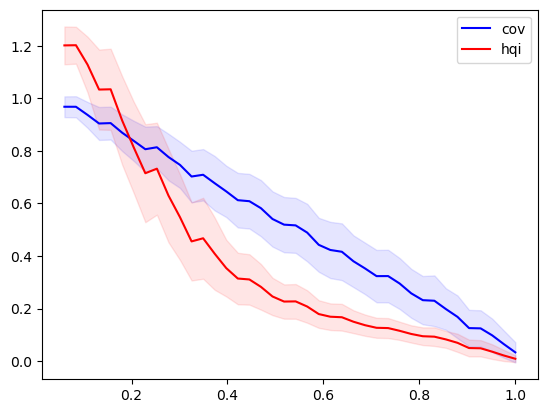

In [86]:
m = 30
res_dict_hqi = defaultdict(list) 
for alpha in np.linspace(0.06,1, 40):
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)

    for i in range(500):
        
        idx = np.array([1] * m + [0] * (smx.shape[0]-m)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        prediction_sets, empirical_coverage = conform_pref_2(cal_smx, val_smx, cal_labels, m, alpha, val_labels)
        #prediction_sets.sum(1).mean(), empirical_coverage
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        
    res_dict_hqi['alpha'].append(alpha)    
    res_dict_hqi['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict_hqi['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict_hqi['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict_hqi['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())

res_df_hqi = pd.DataFrame(res_dict_hqi)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['cov_mean']-res_df_hqi['cov_sd']), (res_df_hqi['cov_mean']+res_df_hqi['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['set_size_mean']/15, c='r', label='hqi')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['set_size_mean']-res_df_hqi['set_size_sd'])/15, (res_df_hqi['set_size_mean']+res_df_hqi['set_size_sd'])/15, color = 'r', alpha=.1)

_ = plt.legend()

In [81]:
clf = model_logReg(C=7)
clf.train_data(X_train_1, y_train_1)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test_1)
clf.score(X_test_1, y_test_1)

0.97

In [82]:
smx = clf.model.predict_proba(X_test_1)

labels = y_test_1.reset_index().merge(label_table)['id'].to_numpy()

idx = np.array([1] * m + [0] * (smx.shape[0]-m)) > 0
np.random.shuffle(idx)
cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_labels, val_labels = labels[idx], labels[~idx]

prediction_sets, empirical_coverage = conform_pref(cal_smx, val_smx, cal_labels, m, alpha, val_labels)
prediction_sets.sum(1).mean(), empirical_coverage

(0.07142857142857142, 0.07142857142857142)

In [87]:
res_dict_log = defaultdict(list) 
for alpha in np.linspace(0.1,1, 40):
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)

    for i in range(500):
        
        idx = np.array([1] * m + [0] * (smx.shape[0]-m)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        prediction_sets, empirical_coverage = conform_pref_2(cal_smx, val_smx, cal_labels, m, alpha, val_labels)
        #prediction_sets.sum(1).mean(), empirical_coverage
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        
    res_dict_log['alpha'].append(alpha)    
    res_dict_log['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict_log['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict_log['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict_log['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())

res_df_log = pd.DataFrame(res_dict_log)


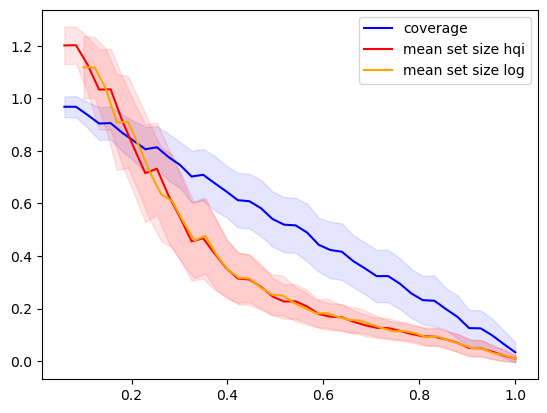

In [88]:
#_ = plt.plot(res_df_log['alpha'], res_df_log['cov_mean'], c='g')
#_ = plt.fill_between(res_df_log['alpha'], (res_df_log['cov_mean']-res_df_log['cov_sd']), (res_df_log['cov_mean']+res_df_log['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['cov_mean'], label='coverage', c='b')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['cov_mean']-res_df_hqi['cov_sd']), (res_df_hqi['cov_mean']+res_df_hqi['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['set_size_mean']/15, c='r', label='mean set size hqi')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['set_size_mean']-res_df_hqi['set_size_sd'])/15, (res_df_hqi['set_size_mean']+res_df_hqi['set_size_sd'])/15, color = 'r', alpha=.1)

_ = plt.plot(res_df_log['alpha'], res_df_log['set_size_mean']/15, c='orange', label='mean set size log')
_ = plt.fill_between(res_df_log['alpha'], (res_df_log['set_size_mean']-res_df_log['set_size_sd'])/15, (res_df_log['set_size_mean']+res_df_log['set_size_sd'])/15, color = 'r', alpha=.1)

_ = plt.legend()

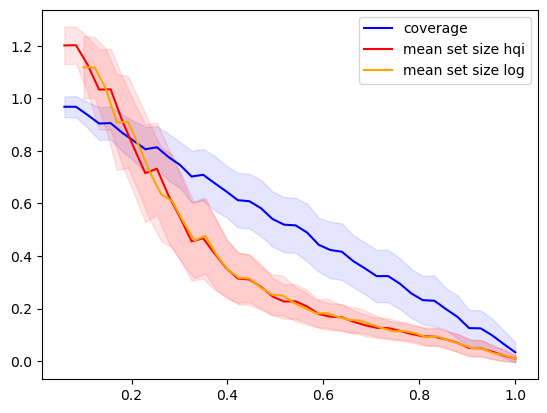

In [89]:
#_ = plt.plot(res_df_log['alpha'], res_df_log['cov_mean'], c='g')
#_ = plt.fill_between(res_df_log['alpha'], (res_df_log['cov_mean']-res_df_log['cov_sd']), (res_df_log['cov_mean']+res_df_log['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['cov_mean'], label='coverage', c='b')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['cov_mean']-res_df_hqi['cov_sd']), (res_df_hqi['cov_mean']+res_df_hqi['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['set_size_mean']/15, c='r', label='mean set size hqi')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['set_size_mean']-res_df_hqi['set_size_sd'])/15, (res_df_hqi['set_size_mean']+res_df_hqi['set_size_sd'])/15, color = 'r', alpha=.1)

_ = plt.plot(res_df_log['alpha'], res_df_log['set_size_mean']/15, c='orange', label='mean set size log')
_ = plt.fill_between(res_df_log['alpha'], (res_df_log['set_size_mean']-res_df_log['set_size_sd'])/15, (res_df_log['set_size_mean']+res_df_log['set_size_sd'])/15, color = 'r', alpha=.1)

_ = plt.legend()

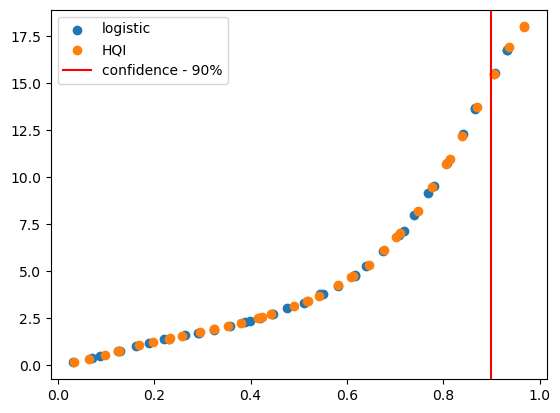

In [90]:
plt.scatter(res_df_log['cov_mean'], res_df_log['set_size_mean'], label='logistic')
plt.scatter(res_df_hqi['cov_mean'], res_df_hqi['set_size_mean'], label='HQI')
plt.axvline(x = 0.90, color = 'r', label = 'confidence - 90%')
plt.legend()

## Aged plastics

In [101]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]

#df_R = 1-df_R
#df_R = np.exp(-df_R/.1)

df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()

#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
#smx = (smx / smx.sum(1)[:,None])
#smx = 1-smx
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())}))['id'].to_numpy()

# Problem setup
n=100 # number of calibration points
alpha = 0.1 # 1-alpha is the desired coverage

In [102]:
idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
np.random.shuffle(idx)
cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_labels, val_labels = labels[idx], labels[~idx]

prediction_sets, empirical_coverage = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
prediction_sets.sum(1).mean(), empirical_coverage

(1.5903614457831325, 0.8554216867469879)

In [103]:
pd.concat([pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(83),val_labels]}).groupby('label').mean()* 100,
 pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(83),val_labels]}).groupby('label').mean()* 100])

,coverage
label,
2,100.000000
4,100.000000
5,90.909091
7,100.000000
8,66.666667
10,70.000000
11,100.000000
12,100.000000
13,100.000000


['Cotton']


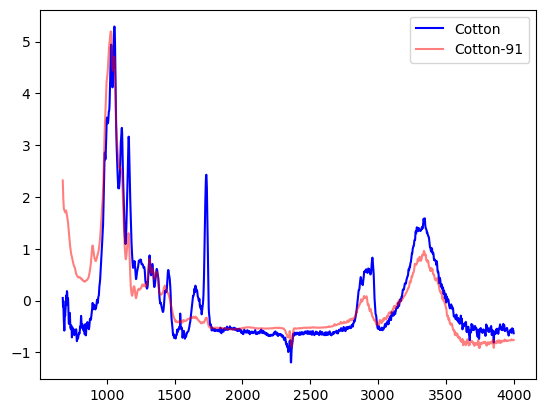

['Cotton']


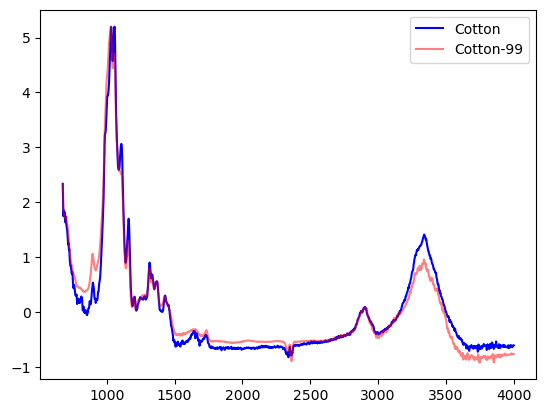

[]


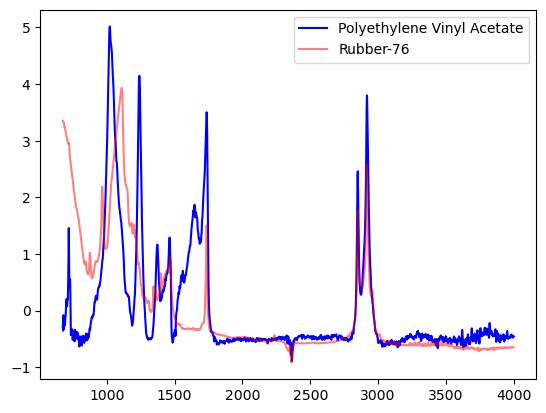

['Polyethylene Vinyl Acetate']


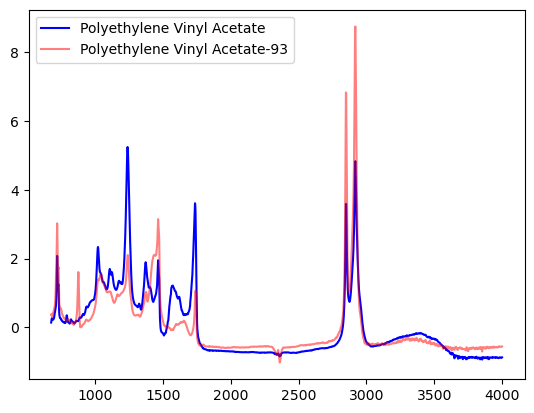

['Acrylic', 'Polyethylene Vinyl Acetate']


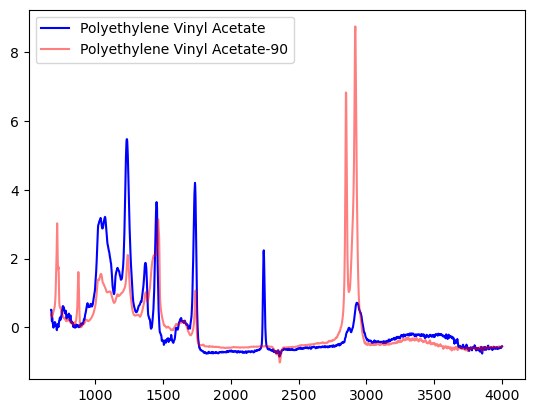

['Polycarbonate']


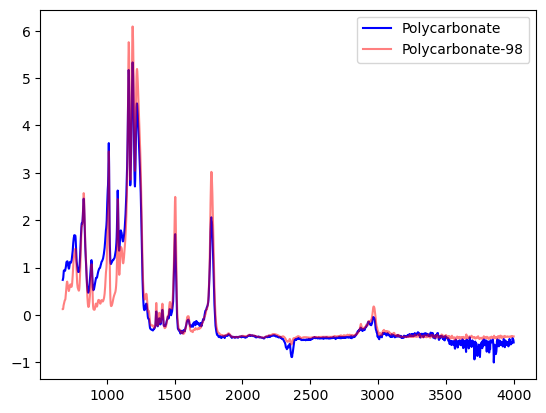

['Polyethylene']


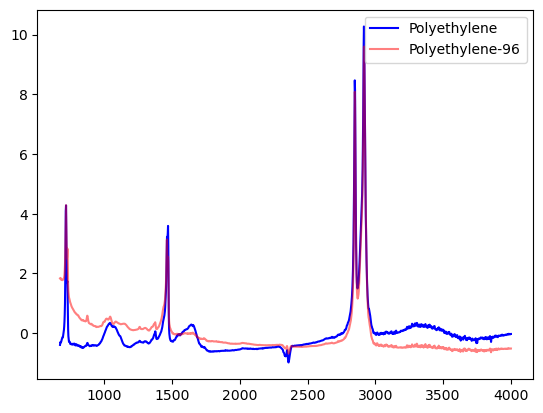

['Polyethylene Vinyl Acetate']


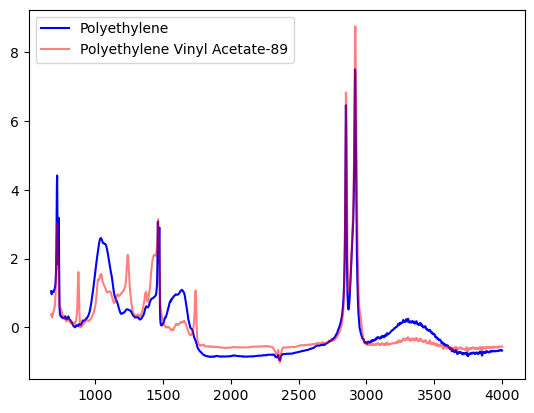

['Polyethylene', 'Polyethylene Vinyl Acetate']


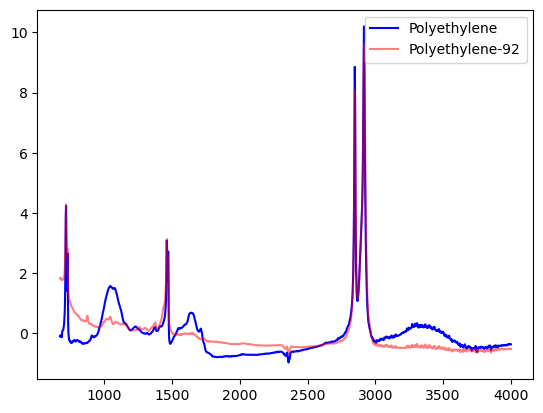

['Polyethylene']


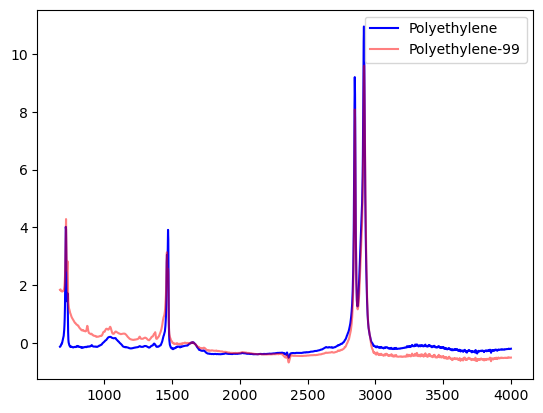

['Polyethylene', 'Polyethylene Vinyl Acetate']


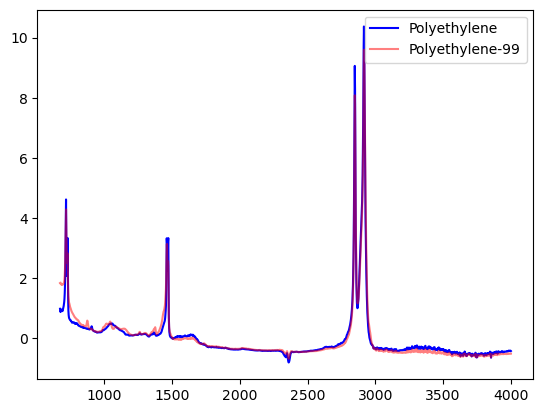

['Polyethylene', 'Polyethylene Vinyl Acetate']


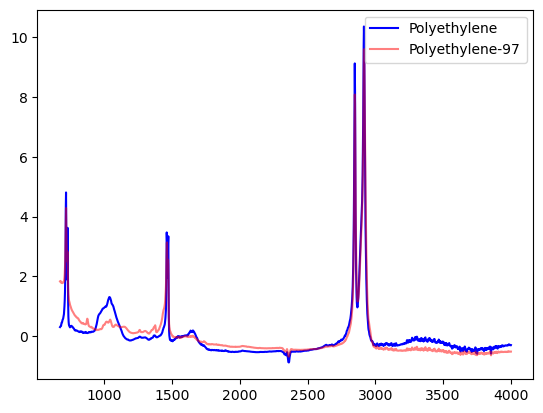

['Polyethylene', 'Polyethylene Vinyl Acetate']


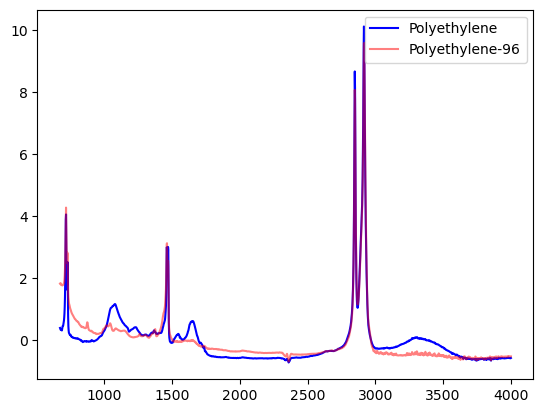

['Polyethylene']


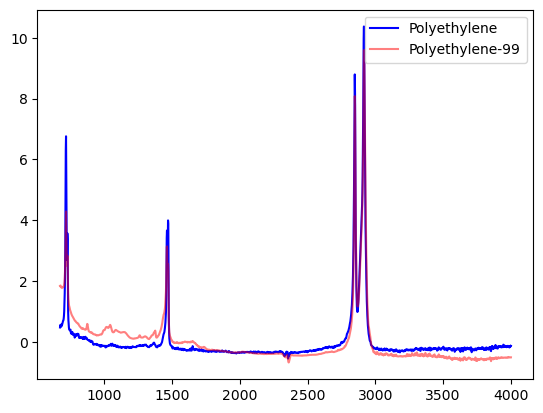

[]


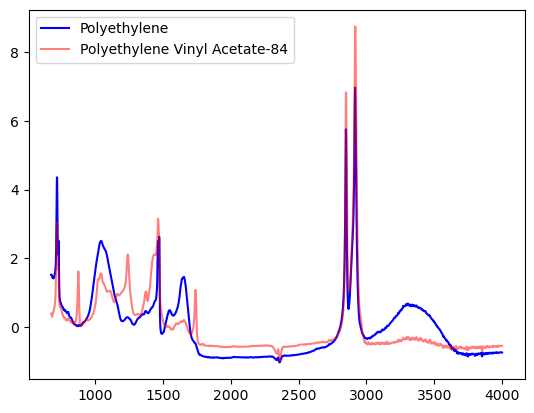

['Polyethylene', 'Rubber']


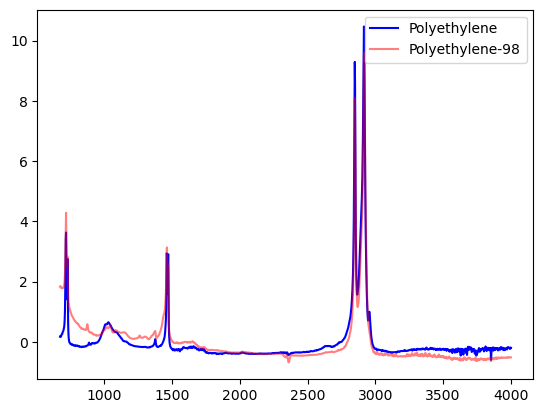

['Polyethylene']


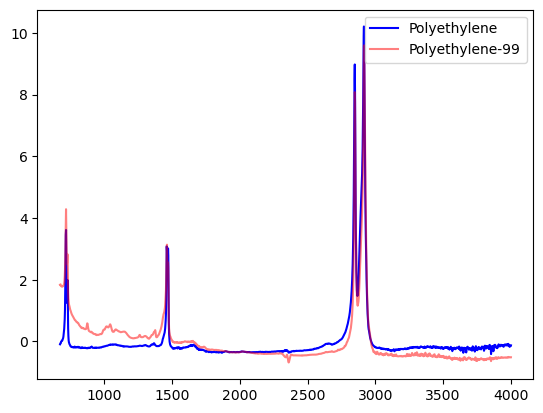

['Polyethylene', 'Polyethylene Vinyl Acetate']


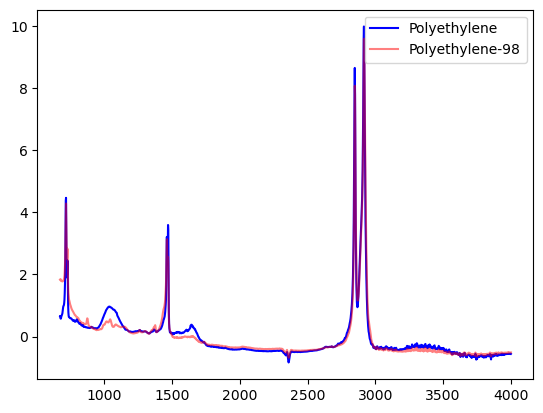

['Polyethylene Terephthalate']


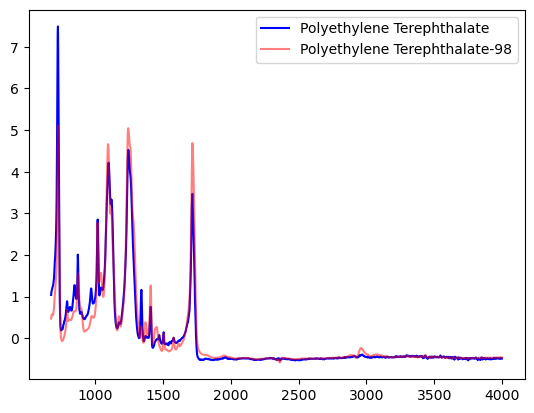

['Polyethylene Terephthalate']


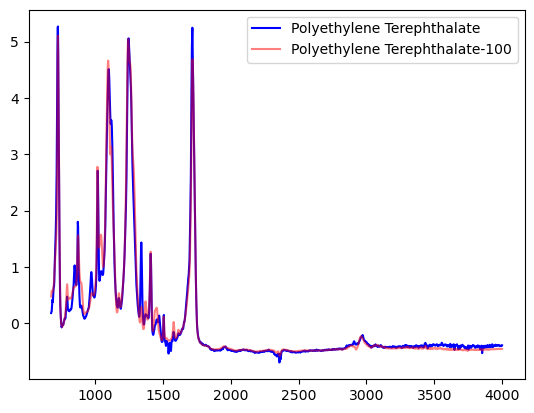

['Polyethylene Terephthalate']


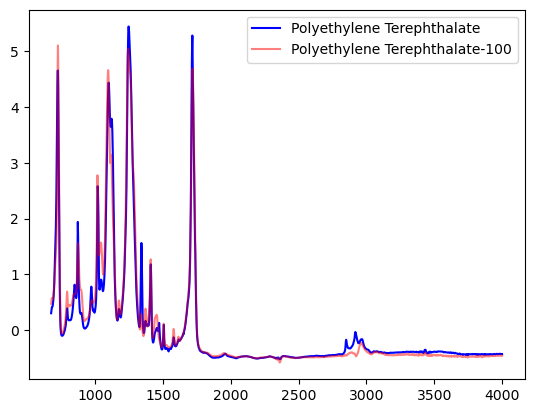

['Polyethylene Terephthalate']


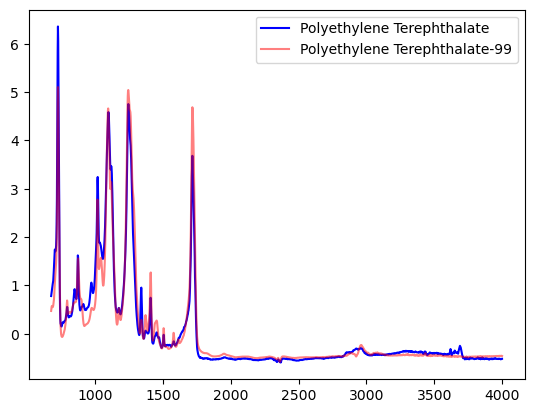

['Polyethylene Terephthalate']


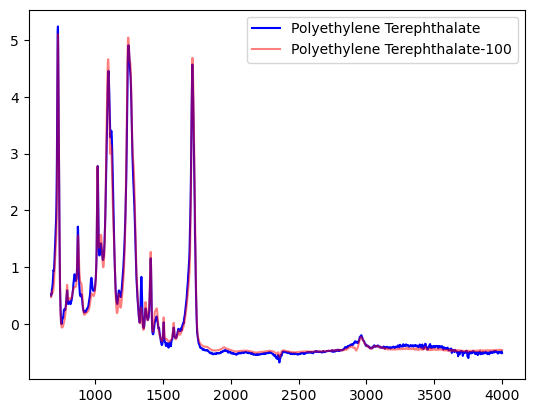

['Polyethylene Terephthalate']


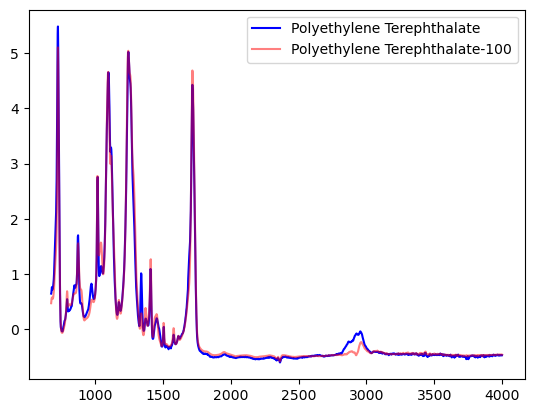

['Polyethylene Terephthalate']


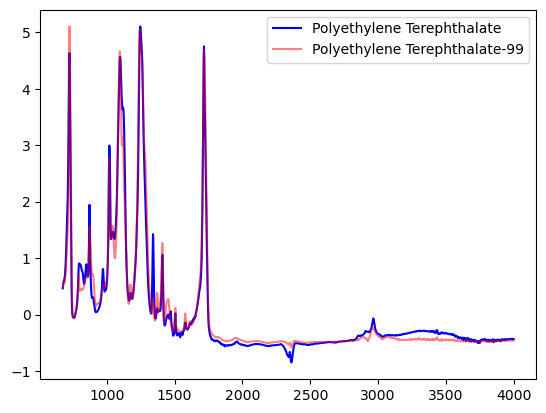

['Polyethylene Terephthalate']


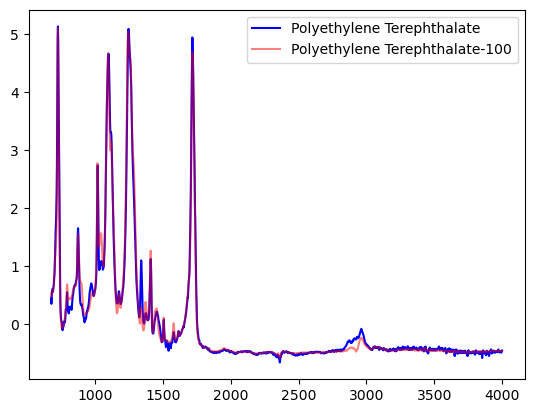

['Polyethylene Terephthalate']


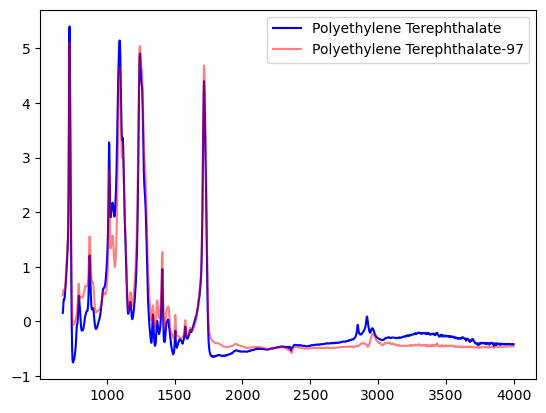

['Polyethylene Terephthalate']


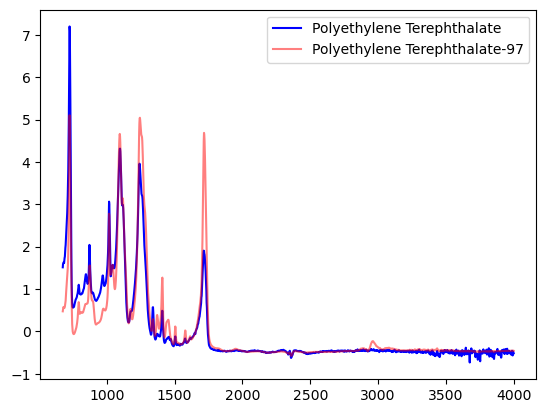

['Polyethylene Terephthalate']


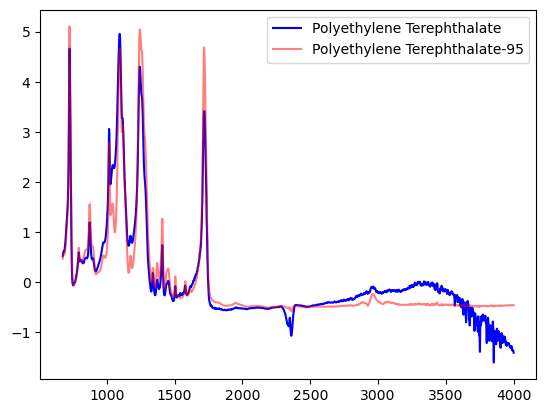

['Polyethylene Terephthalate']


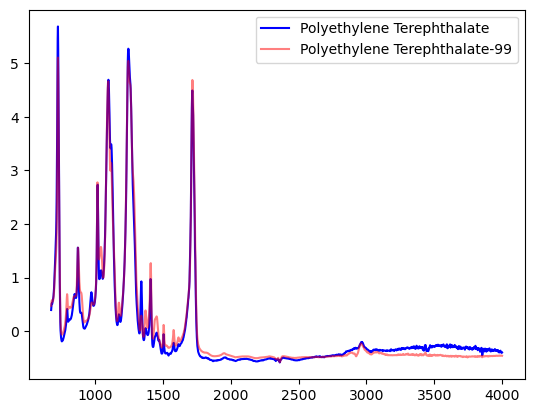

['Polyethylene Terephthalate']


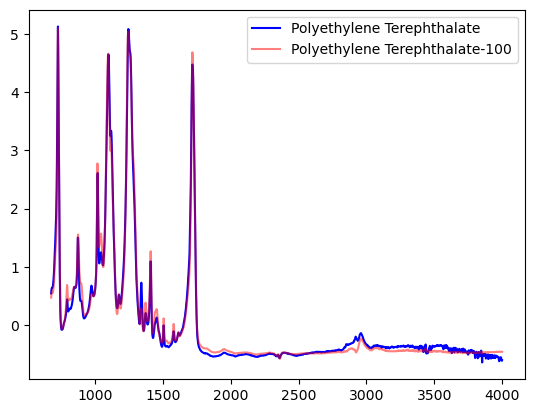

['Polyethylene Terephthalate']


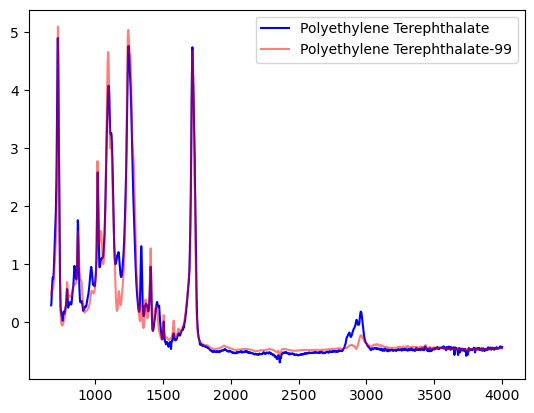

['Polypropylene', 'Rubber']


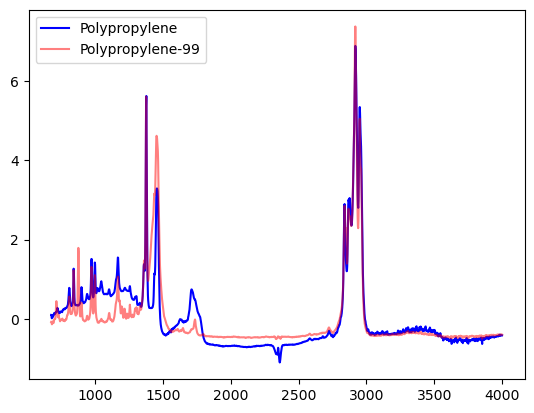

['Polypropylene', 'Rubber']


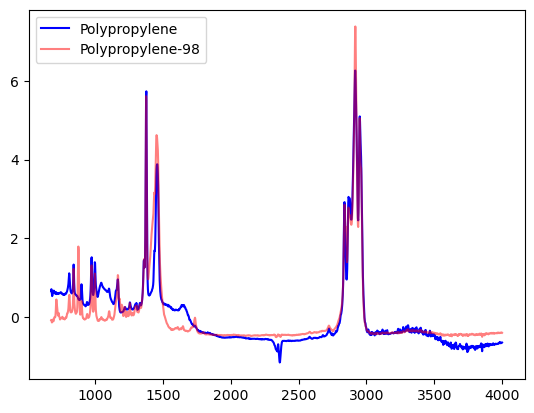

['Polypropylene']


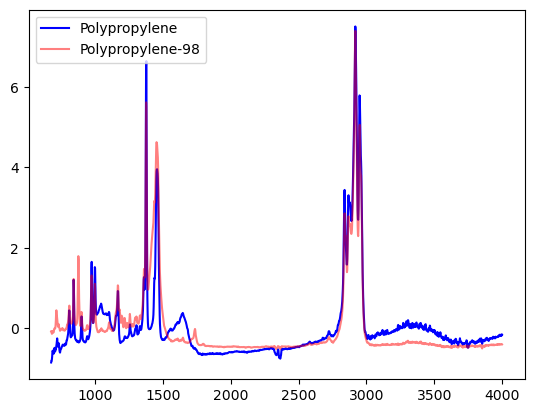

['Polypropylene']


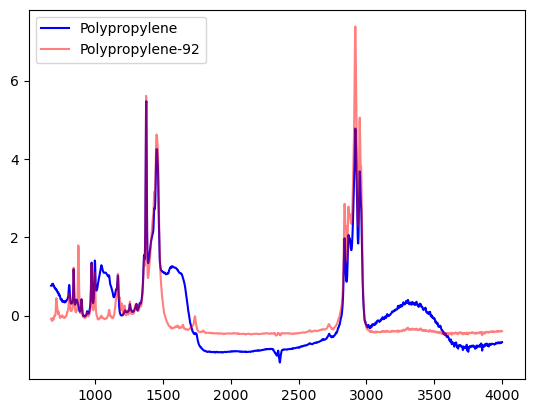

['Cotton', 'Rubber']


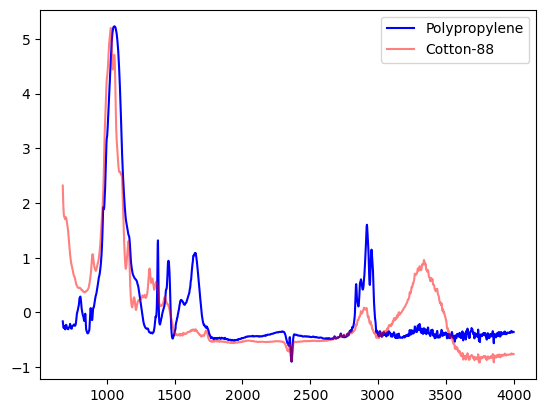

['Polypropylene']


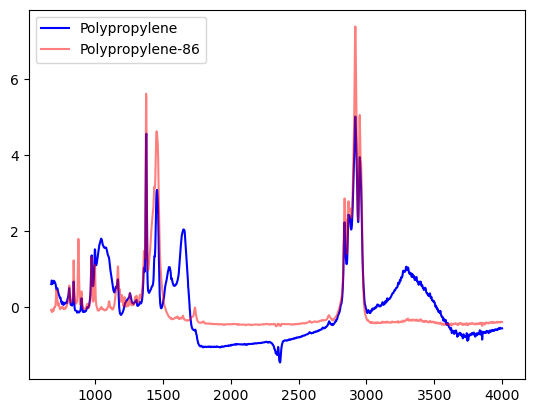

['Polypropylene', 'Rubber']


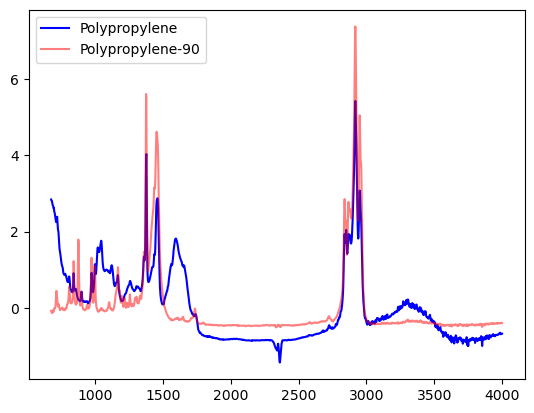

['Polypropylene', 'Rubber']


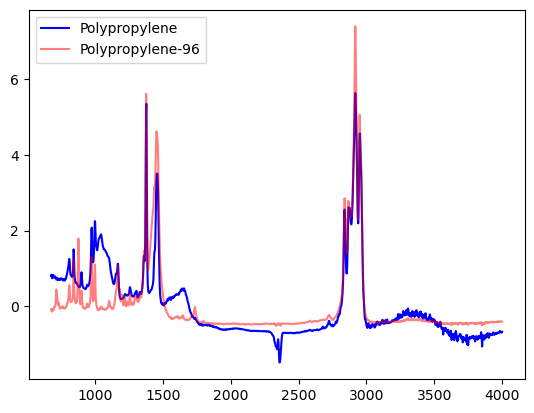

[]


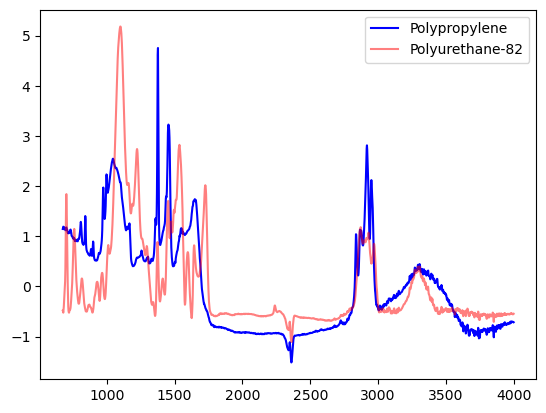

['Polypropylene', 'Rubber']


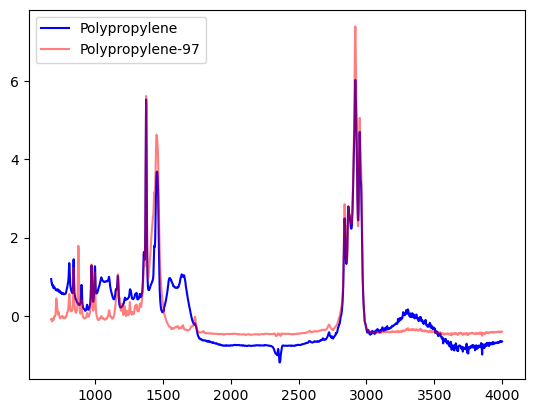

[]


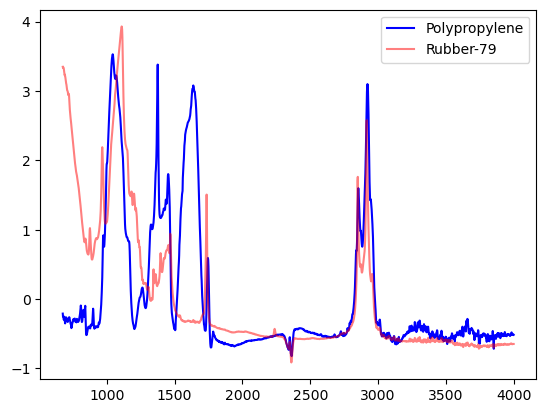

['Polypropylene', 'Rubber']


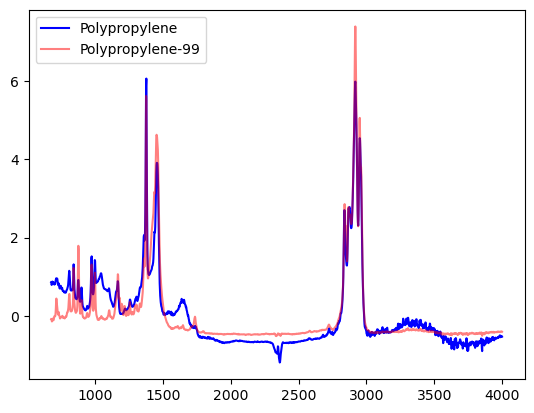

['Polypropylene']


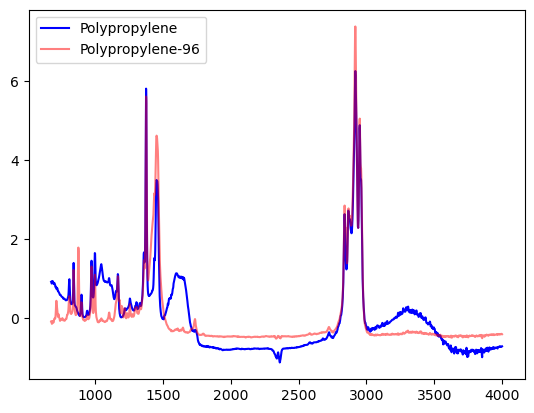

['Polypropylene']


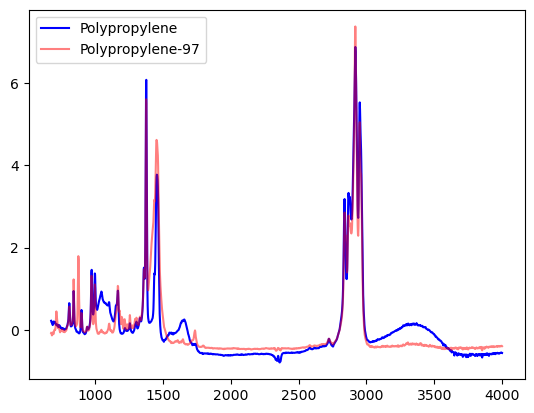

['Polypropylene']


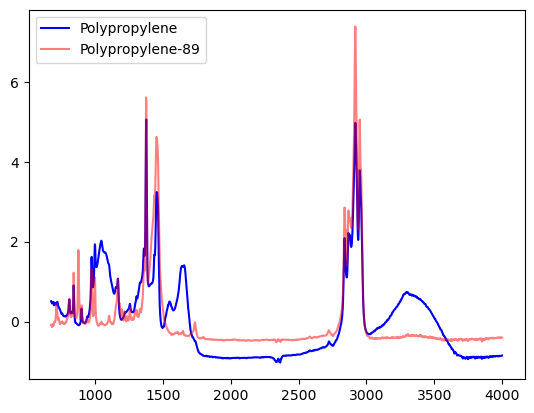

['Polypropylene']


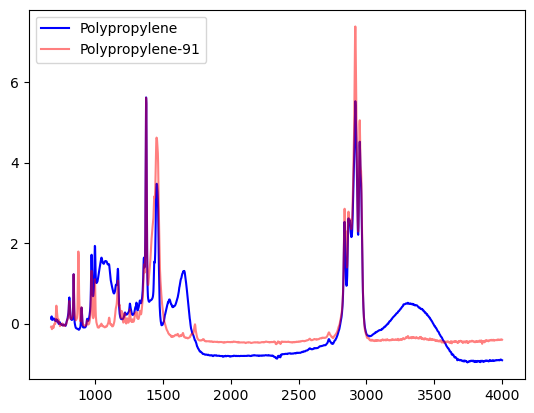

['Polypropylene']


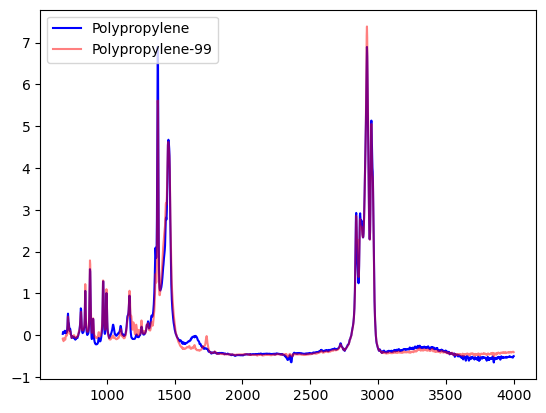

['Polypropylene']


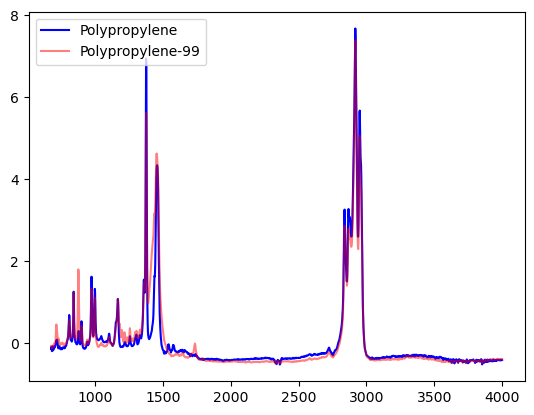

[]


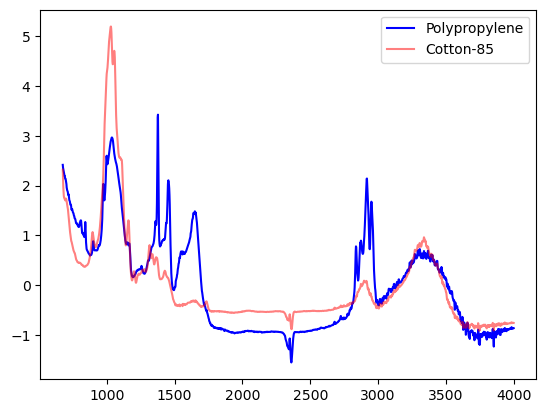

['Polypropylene']


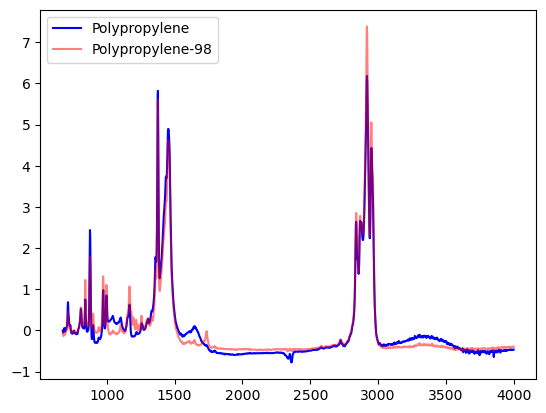

[]


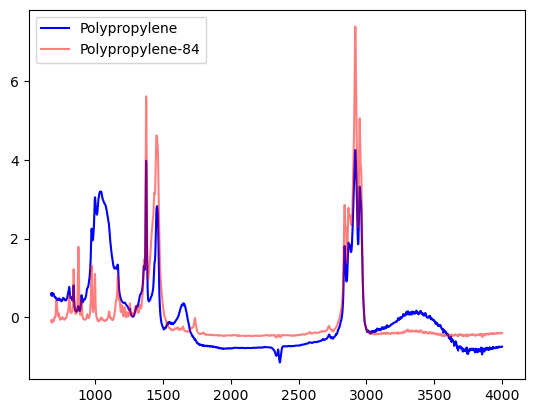

[]


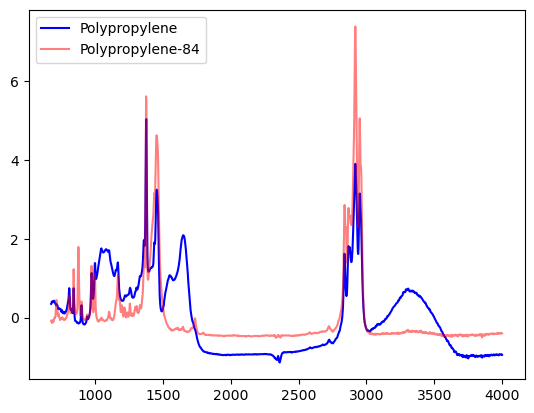

['Polypropylene']


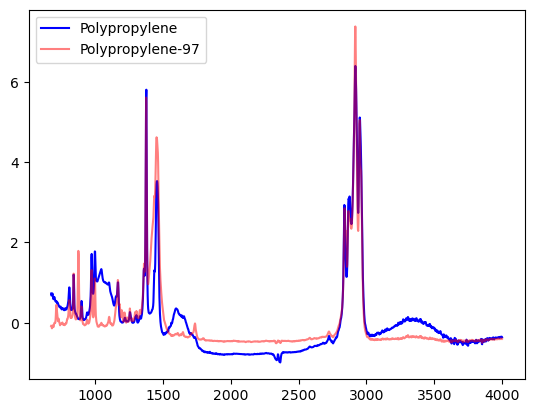

[]


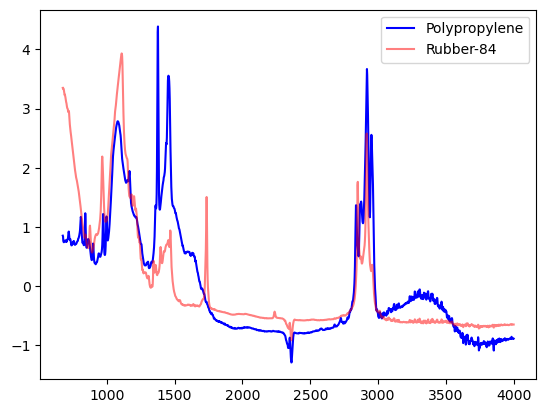

['Polypropylene', 'Rubber']


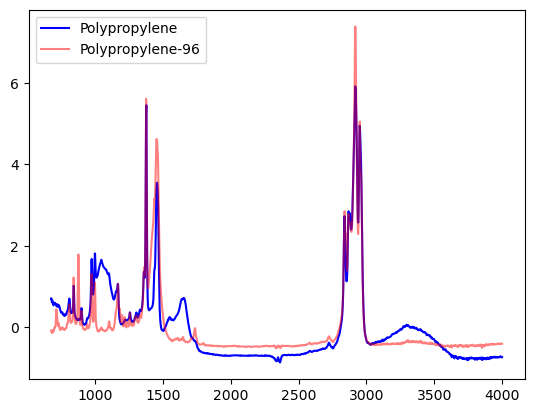

['Polypropylene']


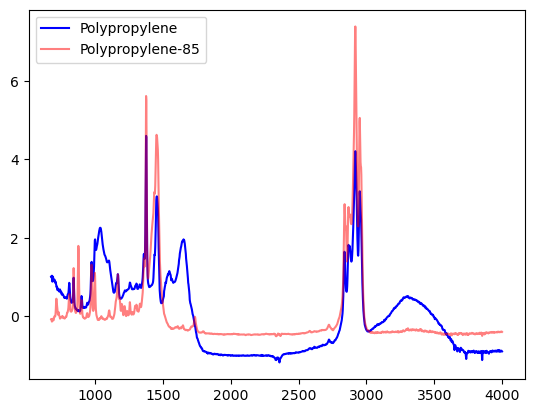

[]


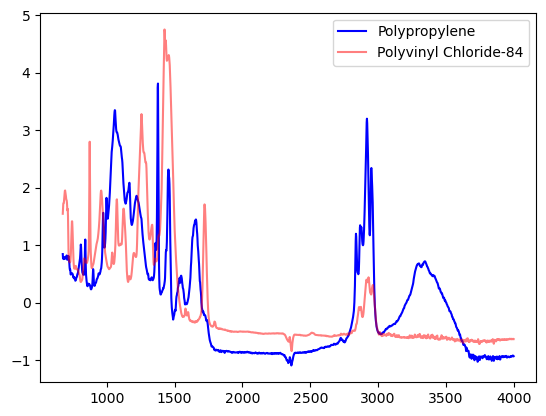

['Polypropylene', 'Rubber']


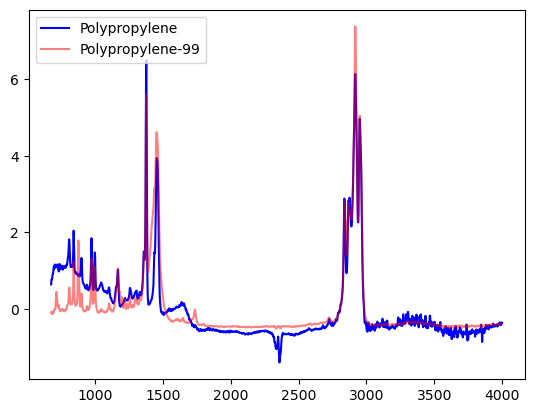

['Acrylonitrile Butadiene Styrene', 'Polystyrene']


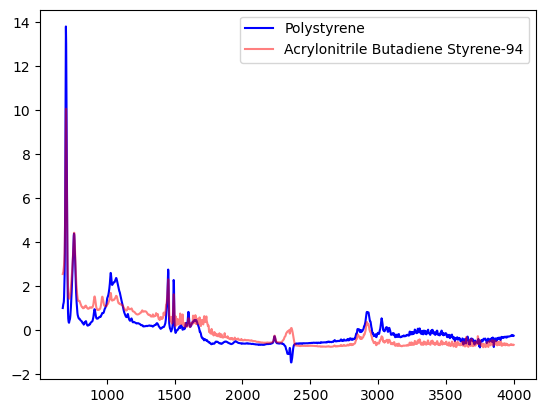

['Polyurethane']


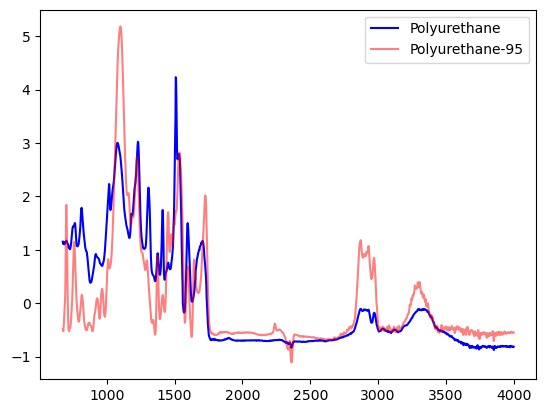

['Polyurethane']


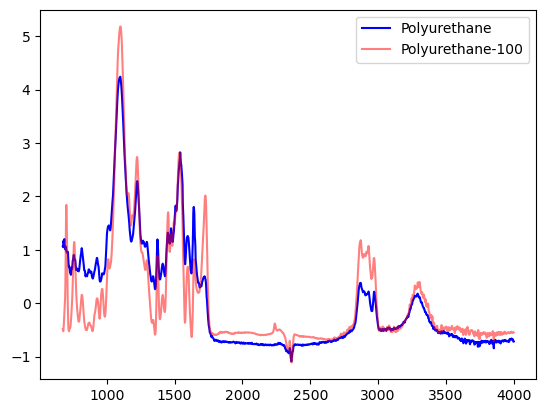

['Polyvinyl Chloride']


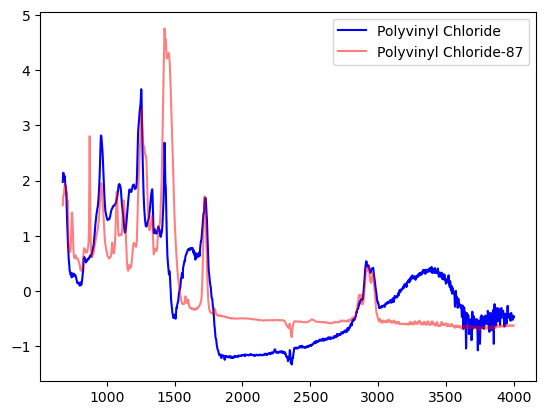

['Polyethylene Terephthalate', 'Polyvinyl Chloride']


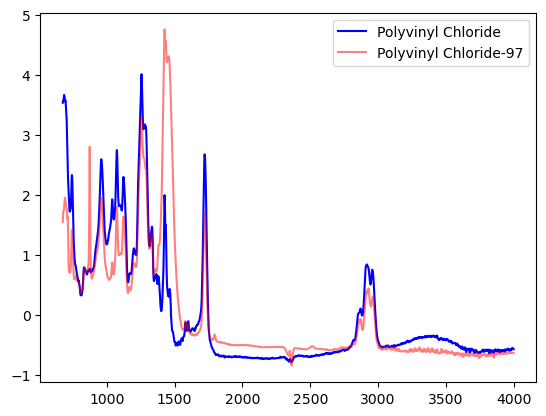

['Polyurethane', 'Polyvinyl Chloride']


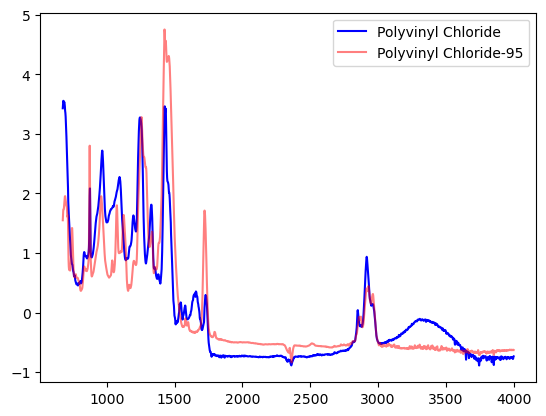

In [104]:
pred_hqi, score_hqi = corr_matching(X_train, pd.Series(y_train_), X_test[~idx], r_min=0)
pred_hqi = pred_hqi.to_numpy()

label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})
prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(83)]

for i in range(prediction_sets.shape[0]):
    if len(prediction_sets_label[i]) >2:
        continue
    print(prediction_sets_label[i])

    plt.plot(wl_list, -X_test[~idx].reset_index(drop=True).loc[i,:].to_numpy(), c='b', label=label_table.iloc[val_labels[i],1])

    #plt.plot(wl_list, X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list, -X_train[y_train_==pred_hqi[i]].reset_index(drop=True).iloc[0,:].to_numpy(), c='r', alpha=.5, label=pred_hqi[i] + '-' + str(round(score_hqi[i]*100)))

    plt.legend()

    plt.show()


In [105]:
n / (n + smx.shape[0]-n)

0.546448087431694

In [125]:
res_dict_hqi = defaultdict(list) 
cov_by_label = defaultdict(list)
set_size_by_label = defaultdict(list)
for alpha in np.linspace(0.01,1, 40):
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)

    for i in range(500):
        
        idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        prediction_sets, empirical_coverage = conform_pref_2(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        #prediction_sets.sum(1).mean(), empirical_coverage
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        
        cov_by_label[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(83),val_labels]}).groupby('label').mean()* 100
    )
        set_size_by_label[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_hqi['alpha'].append(alpha)    
    res_dict_hqi['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict_hqi['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict_hqi['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict_hqi['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())
    
    
res_df_hqi = pd.DataFrame(res_dict_hqi)


In [107]:
cov_by_label.keys()

dict_keys([0.01, 0.03538461538461538, 0.06076923076923077, 0.08615384615384615, 0.11153846153846153, 0.13692307692307693, 0.16230769230769232, 0.18769230769230769, 0.21307692307692308, 0.23846153846153847, 0.26384615384615384, 0.28923076923076924, 0.31461538461538463, 0.34, 0.36538461538461536, 0.39076923076923076, 0.41615384615384615, 0.44153846153846155, 0.46692307692307694, 0.4923076923076923, 0.5176923076923077, 0.5430769230769231, 0.5684615384615385, 0.5938461538461538, 0.6192307692307693, 0.6446153846153846, 0.67, 0.6953846153846154, 0.7207692307692307, 0.7461538461538462, 0.7715384615384615, 0.796923076923077, 0.8223076923076923, 0.8476923076923076, 0.8730769230769231, 0.8984615384615384, 0.9238461538461539, 0.9492307692307692, 0.9746153846153846, 1.0])

In [108]:
set_size_by_label_table = (pd.concat(set_size_by_label[0.11153846153846153]).
 groupby('label').
 mean().
 merge(label_table, left_index=True, right_on='id'))#.
 #merge(pd.concat(set_size_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
del set_size_by_label_table['id']
set_size_by_label_table.columns = ['set size','polymer']
set_size_by_label_table = np.round(set_size_by_label_table.set_index('polymer').sort_values('set size'), 2)
set_size_by_label_table

,set size
polymer,
Cotton,2.39
Acrylonitrile Butadiene Styrene,2.40
Polyethylene,2.43
Polystyrene,2.54
Polyvinyl Chloride,2.58
Polyurethane,2.63
Polypropylene,2.67
Polyethylene Terephthalate,2.68
Polyethylene Vinyl Acetate,2.77


In [112]:
cov_by_label_table = (pd.concat(cov_by_label[0.11153846153846153]).
 groupby('label').
 mean().
 merge(label_table, left_index=True, right_on='id').
 merge(pd.concat(cov_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
del cov_by_label_table['id']
cov_by_label_table.columns = ['coverage','polymer','# samples']
cov_by_label_table = np.round(cov_by_label_table.set_index('polymer').sort_values('coverage'), 2)
cov_by_label_table

,coverage,# samples
polymer,,
Polypropylene,83.62,500
Polystyrene,87.03,500
Polyethylene,87.73,500
Cotton,98.86,500
Polyvinyl Chloride,99.73,499
Acrylonitrile Butadiene Styrene,100.00,243
Polycarbonate,100.00,228
Polyethylene Terephthalate,100.00,500
Polyethylene Vinyl Acetate,100.00,479


In [113]:
pd.merge(cov_by_label_table, set_size_by_label_table, left_index = True, right_index = True).iloc[:, [0,2]]

,coverage,set size
polymer,,
Polypropylene,83.62,2.67
Polystyrene,87.03,2.54
Polyethylene,87.73,2.43
Cotton,98.86,2.39
Polyvinyl Chloride,99.73,2.58
Acrylonitrile Butadiene Styrene,100.00,2.40
Polycarbonate,100.00,2.80
Polyethylene Terephthalate,100.00,2.68
Polyethylene Vinyl Acetate,100.00,2.77


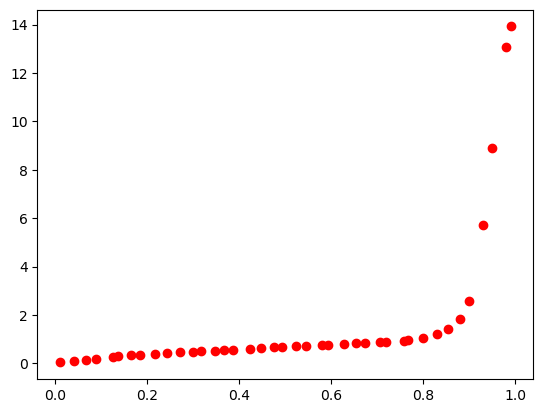

In [114]:
plt.scatter(res_df_hqi['cov_mean'], res_df_hqi['set_size_mean'], c='red', label='HQI')

In [115]:
clf = model_logReg(C=7)
clf.train_data(x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test)
clf.score(X_test, y_test)

0.912568306010929

In [116]:
smx = clf.model.predict_proba(X_test)
label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})
labels = y_test.reset_index().merge(label_table)['id'].to_numpy()

idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
np.random.shuffle(idx)
cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_labels, val_labels = labels[idx], labels[~idx]

prediction_sets, empirical_coverage = conform_pref(cal_smx, val_smx, cal_labels, n, 0.1, val_labels)
prediction_sets.sum(1).mean(), empirical_coverage

(0.9879518072289156, 0.927710843373494)

[]


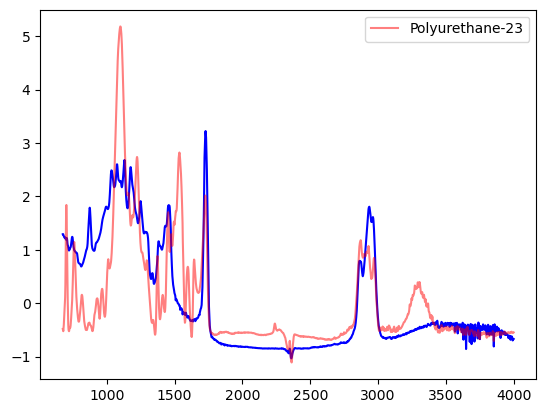

In [117]:
score_log = clf.model.predict_proba(X_test[~idx]).max(1)
pred_log = clf.model.predict(X_test[~idx])

label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})
prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(83)]

for i in range(prediction_sets.shape[0]):
    if len(prediction_sets_label[i]) > 0:
        continue
    print(prediction_sets_label[i])

    plt.plot(wl_list, -X_test[~idx].reset_index(drop=True).loc[i,:].to_numpy(), c='b')

    #plt.plot(wl_list, X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list, -X_train[y_train_==pred_log[i]].reset_index(drop=True).iloc[0,:].to_numpy(), c='r', alpha=.5, label=pred_log[i] + '-' + str(round(score_log[i]*100)))

    plt.legend()

    plt.show()


In [131]:
res_dict_log = defaultdict(list) 
cov_by_label = defaultdict(list)
set_size_by_label = defaultdict(list)
for alpha in np.linspace(0.01,1, 40):
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)

    for i in range(500):
        
        idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        prediction_sets, empirical_coverage = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        #prediction_sets.sum(1).mean(), empirical_coverage
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        
        cov_by_label[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(83),val_labels]}).groupby('label').mean()* 100
    )
        set_size_by_label[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_log['alpha'].append(alpha)    
    res_dict_log['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict_log['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict_log['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict_log['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())

res_df_log = pd.DataFrame(res_dict_log)


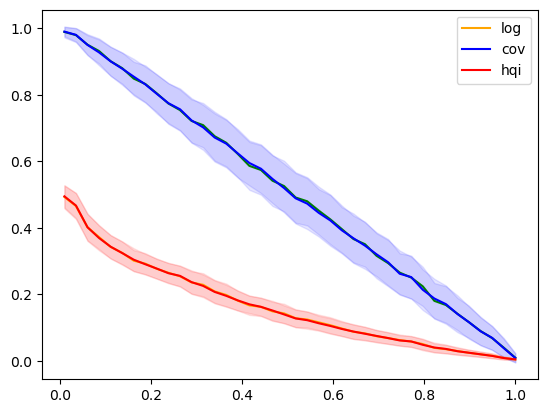

In [127]:
_ = plt.plot(res_df_log['alpha'], res_df_log['cov_mean'], c='g')
_ = plt.fill_between(res_df_log['alpha'], (res_df_log['cov_mean']-res_df_log['cov_sd']), (res_df_log['cov_mean']+res_df_log['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_log['alpha'], res_df_log['set_size_mean']/15, c='orange', label='log')
_ = plt.fill_between(res_df_log['alpha'], (res_df_log['set_size_mean']-res_df_log['set_size_sd'])/15, (res_df_log['set_size_mean']+res_df_log['set_size_sd'])/15, color = 'r', alpha=.1)


_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['cov_mean']-res_df_hqi['cov_sd']), (res_df_hqi['cov_mean']+res_df_hqi['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df_hqi['alpha'], res_df_hqi['set_size_mean']/15, c='r', label='hqi')
_ = plt.fill_between(res_df_hqi['alpha'], (res_df_hqi['set_size_mean']-res_df_hqi['set_size_sd'])/15, (res_df_hqi['set_size_mean']+res_df_hqi['set_size_sd'])/15, color = 'r', alpha=.1)

_ = plt.legend()


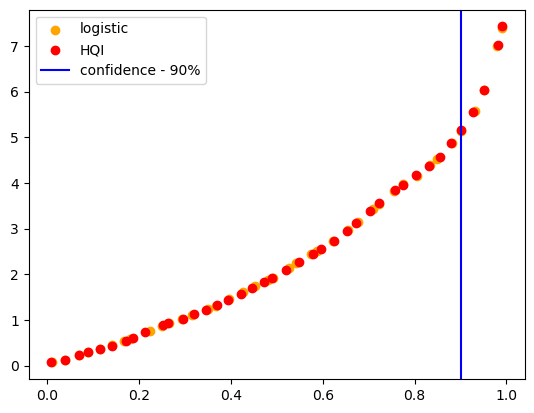

In [128]:
plt.scatter(res_df_log['cov_mean'], res_df_log['set_size_mean'], c='orange', label='logistic')
plt.scatter(res_df_hqi['cov_mean'], res_df_hqi['set_size_mean'], c='red', label='HQI')
plt.axvline(x = 0.90, color = 'b', label = 'confidence - 90%')
plt.legend()

In [1170]:
# Problem setup
n=100 # number of calibration points
alpha = 0.15 # 1-alpha is the desired coverage

idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
np.random.shuffle(idx)
cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_labels, val_labels = labels[idx], labels[~idx]

prediction_sets, empirical_coverage = conform_pref_2(
                                                cal_smx, 
                                                val_smx, 
                                                cal_labels, 
                                                val_labels, 
                                                n, 
                                                alpha)
prediction_sets.sum(1).mean()

1.8795180722891567

In [1171]:
prediction_sets[np.arange(prediction_sets.shape[0]),val_labels][prediction_sets.sum(1) == 2].mean()

0.8666666666666667

(array([ 9.,  0., 35.,  0., 15.,  0.,  9.,  0., 11.,  4.]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

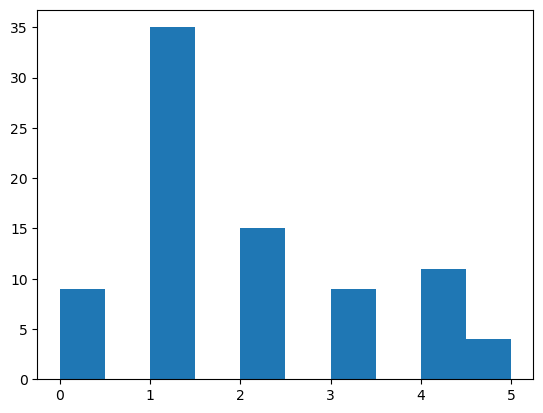

In [1172]:
plt.hist(prediction_sets.sum(1))

In [15]:
prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(83)]

In [1174]:
pred_hqi, score_hqi = corr_matching(X_train, pd.Series(y_train_), X_test[~idx], r_min=0)
pred_hqi = pred_hqi.to_numpy()

In [16]:
#i = 7
for i in range(83):
    print(prediction_sets_label[i])

    plt.plot(wl_list, -X_test[~idx].iloc[i,:].to_numpy(), c='b', label=y_test.to_numpy()[~idx][i])

    plt.plot(wl_list, -X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list, -X_train[y_train==pred_hqi[i]].iloc[0,].to_numpy(), c='r', alpha=.5, label=pred_hqi[i] + '-' + str(round(score_hqi[i]*100)))

    plt.legend()

    plt.show()


['Acrylonitrile Butadiene Styrene', 'Polystyrene']


TypeError: bad operand type for unary ~: 'list'

In [1246]:
spectra_data = Orange.data.Table('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run1.ptir')
spectra_df = (
    spectra_data.
    X_df.T.
    reset_index().
    astype('float32'))
spectra_df.columns = ['wavelength'] + ['particle'+str(i) for i in range(spectra_df.shape[1]-1)]
#spectra_df[np.isnan(spectra_df)] = 0

spectra_df = spectra_df.astype('float32').set_index('wavelength')
spectra_df = ((spectra_df - spectra_df.mean()) / spectra_df.std()).reset_index()
spectra_df_long = spectra_df.melt(id_vars='wavelength')
spectra_df_long.columns = ['wavelength','file_name','intensity']
spectra_df_long['polymer'] = ''
spectra_df_long_int = interpol_spect(spectra_df_long, min_wl=674.9918, max_wl=3999.809,n=1725)

spectra_df_long_int_pivot = spectra_df_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

spectra_2_data = Orange.data.Table('OPTIR/MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2.ptir')
spectra_2_df = (
    spectra_2_data.
    X_df.T.
    reset_index().
    astype('float32'))
spectra_2_df.columns = ['wavelength'] + ['particle'+str(i) for i in range(spectra_2_df.shape[1]-1)]
#spectra_2_df[np.isnan(spectra_df)] = 0

spectra_2_df = spectra_2_df.astype('float32').set_index('wavelength')
spectra_2_df = ((spectra_2_df - spectra_2_df.mean()) / spectra_2_df.std()).reset_index()
spectra_2_df_long = spectra_2_df.melt(id_vars='wavelength')
spectra_2_df_long.columns = ['wavelength','file_name','intensity']
spectra_2_df_long['polymer'] = ''
spectra_2_df_long_int = interpol_spect(spectra_2_df_long, min_wl=674.9918, max_wl=3999.809,n=1725)

spectra_2_df_long_int_pivot = spectra_2_df_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [1249]:
idx_range = np.logical_or(
    np.logical_and(
        wl_list > (spectra_df['wavelength']).min(),
        wl_list < (spectra_df['wavelength'].to_numpy()[np.where(np.isnan(spectra_df['particle0']))]).min()-1,
    ),
    np.logical_and(
        wl_list > (spectra_df['wavelength'].to_numpy()[np.where(np.isnan(spectra_df['particle0']))]).max()+1,
        wl_list < (spectra_df['wavelength']).max(),
    )
)
idx_range

array([False, False, False, ..., False, False, False])

In [1272]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train.loc[:,idx_range],  X_test.loc[:,idx_range])[:n_ref, n_ref:]
df_R = 1-df_R
df_R = np.exp(-df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
cal_smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
cal_smx = (cal_smx / cal_smx.sum(1)[:,None])
#smx = 1-smx
cal_labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())}))['id'].to_numpy()
n = cal_smx.shape[0]

df_R = np.corrcoef(-X_train.loc[:,idx_range],  spectra_df_long_int_pivot.iloc[:,1:].loc[:,idx_range])[:n_ref, n_ref:]
df_R = 1-df_R
df_R = np.exp(-df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
val_smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
val_smx = (val_smx / val_smx.sum(1)[:,None])

alpha = 0.15 # 1-alpha is the desired coverage

In [1273]:
prediction_sets = conform_pref_2(
    cal_smx, 
    val_smx, 
    cal_labels, 
    val_labels=None, 
    n=n, 
    alpha=alpha)

prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(prediction_sets.shape[0])]

In [1274]:
pred_hqi, score_hqi = corr_matching(-X_train.loc[:,idx_range], pd.Series(y_train_), spectra_df_long_int_pivot.iloc[:,1:].loc[:,idx_range], r_min=0)
pred_hqi = pred_hqi.to_numpy()

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


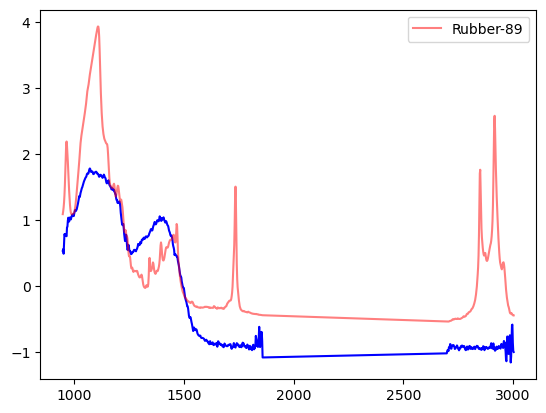

['Polypropylene', 'Polystyrene']


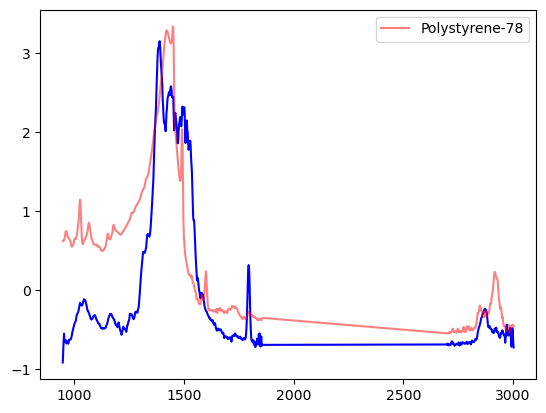

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyurethane', 'Rubber']


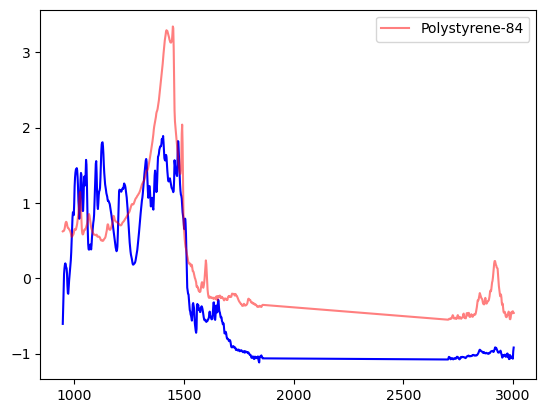

['Acrylonitrile Butadiene Styrene', 'Polyvinyl Chloride', 'Rubber']


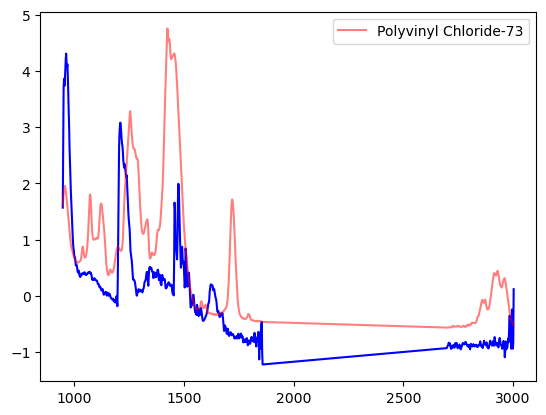

['Acrylonitrile Butadiene Styrene', 'Polyethylene Vinyl Acetate', 'Polyvinyl Chloride', 'Rubber']


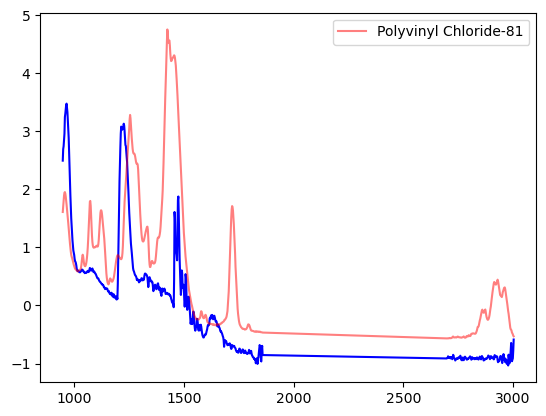

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


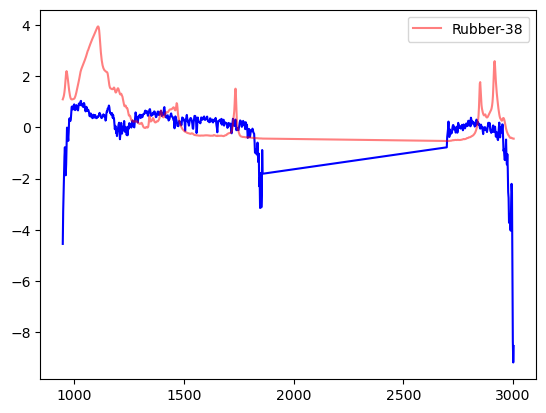

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


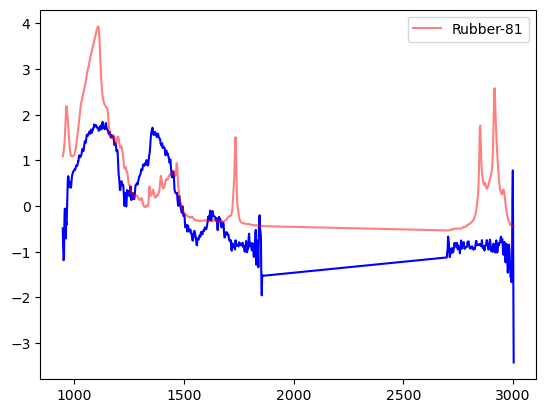

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Rubber']


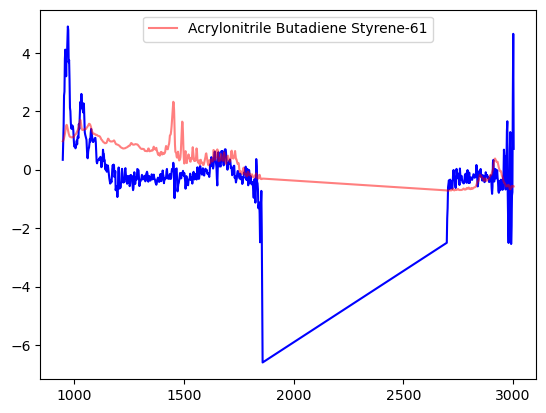

['Cotton', 'Rubber']


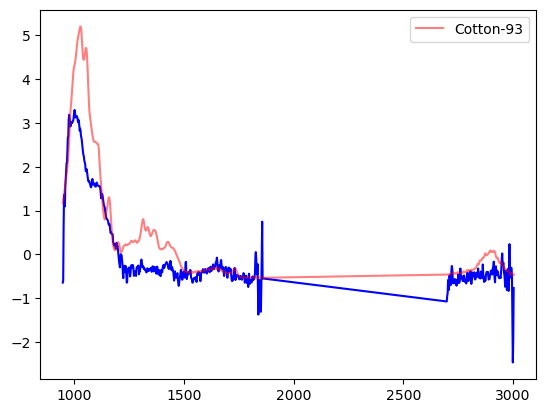

['Cotton', 'Rubber']


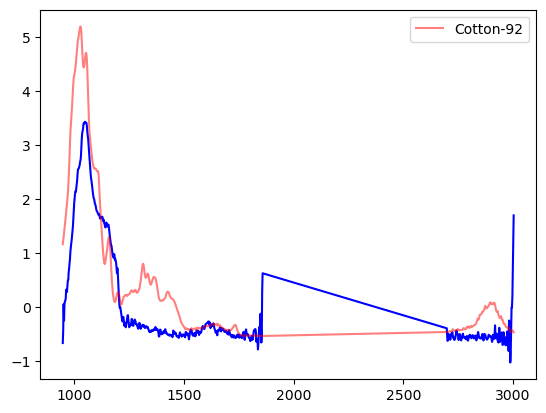

['Cotton', 'Rubber']


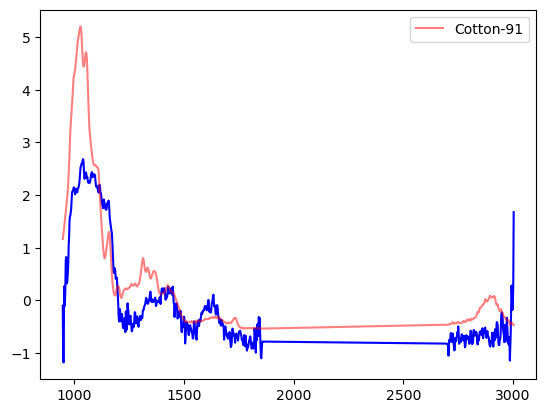

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


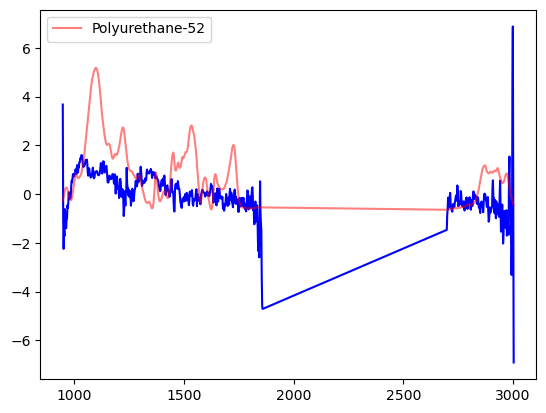

['Polyethylene Terephthalate', 'Polystyrene']


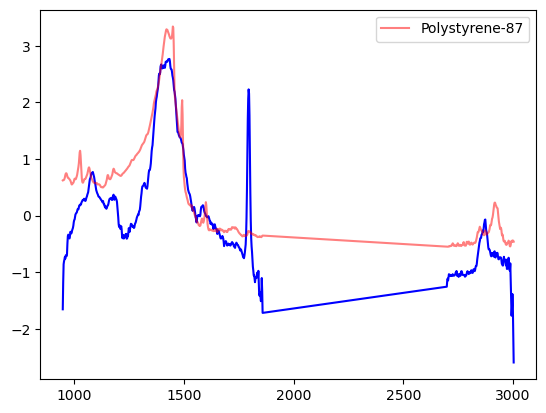

['Cotton', 'Polyurethane', 'Rubber']


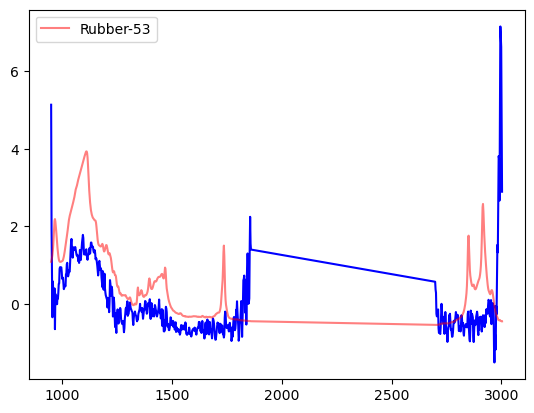

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Polyethylene Terephthalate', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


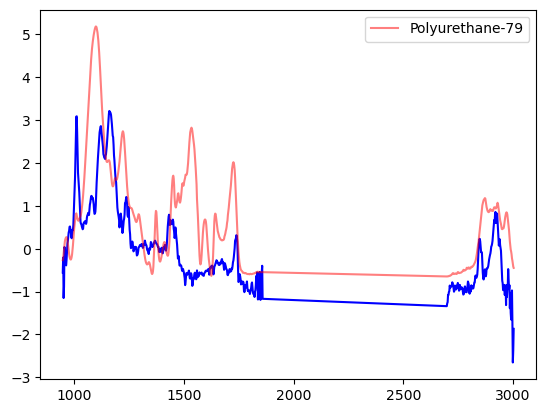

['Polypropylene', 'Polystyrene']


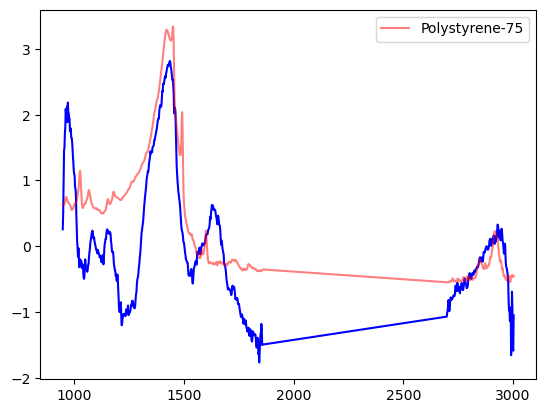

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyurethane', 'Rubber']


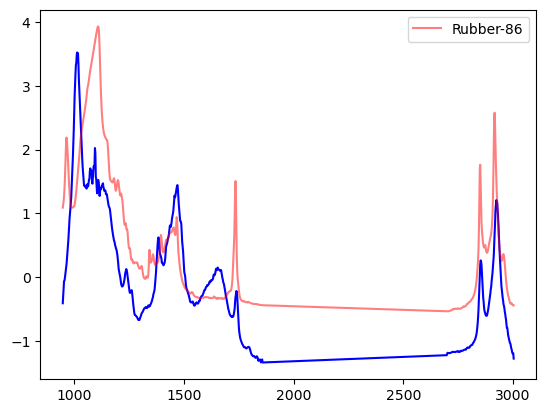

['Cotton', 'Polyurethane', 'Rubber']


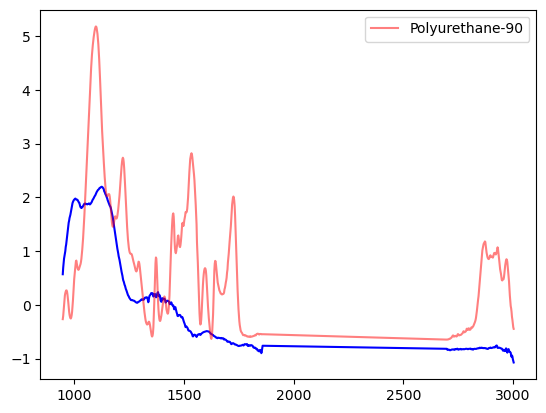

['Rubber']


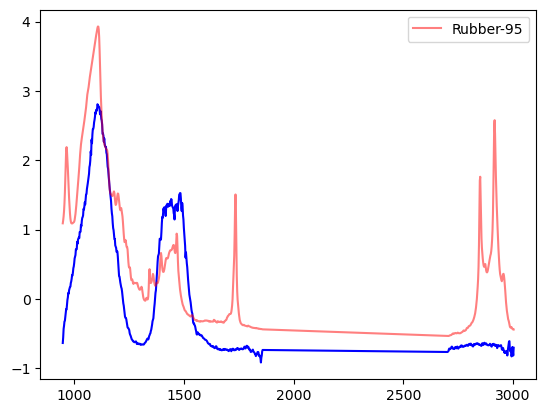

['Rubber']


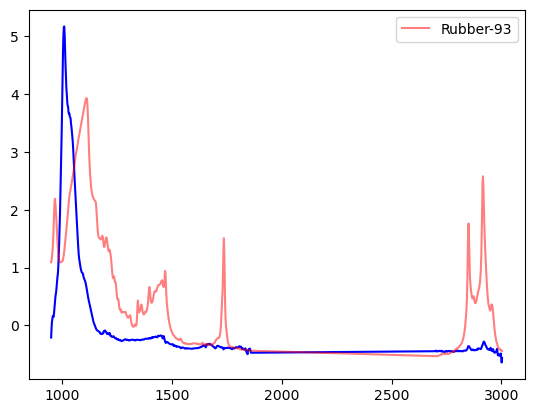

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


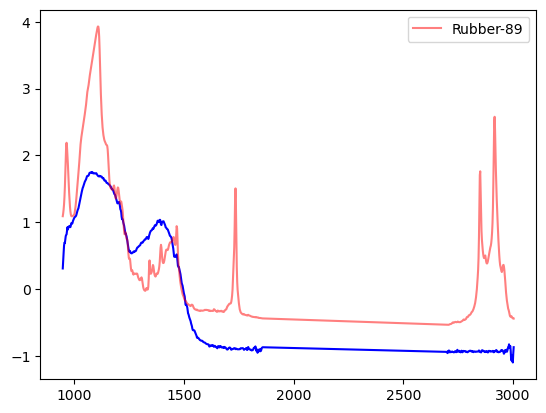

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


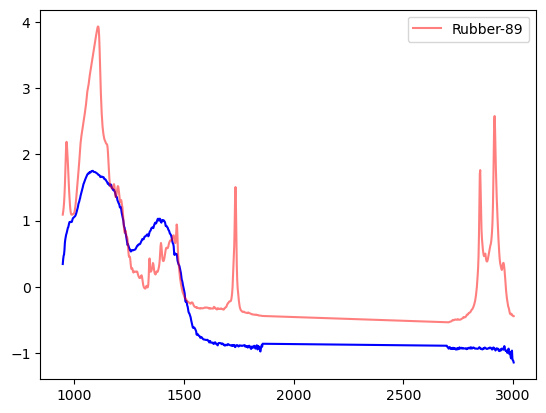

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


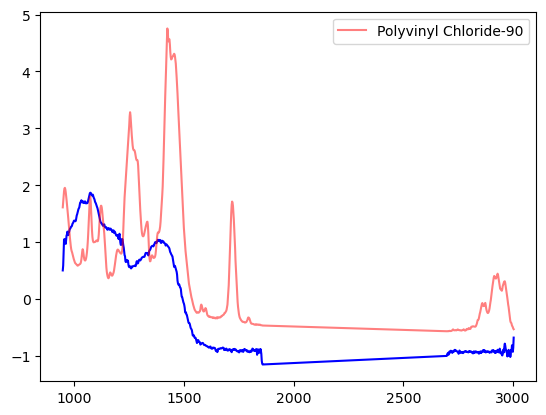

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


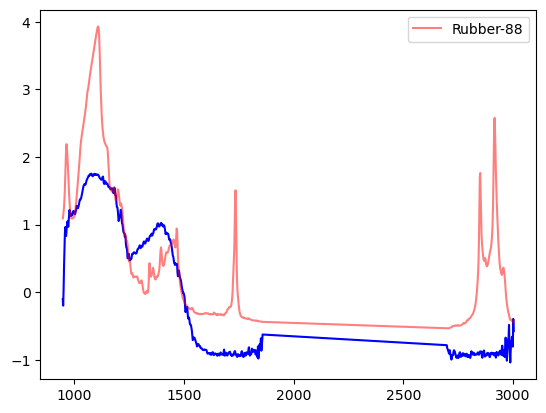

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


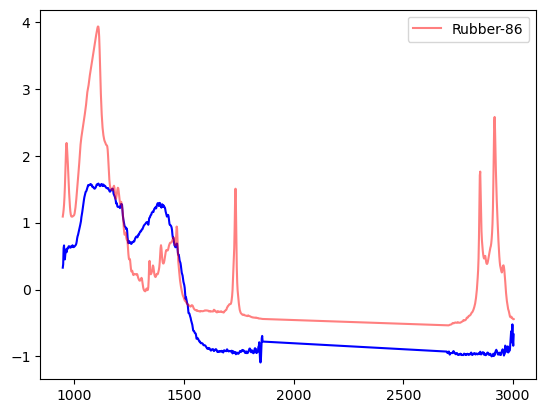

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


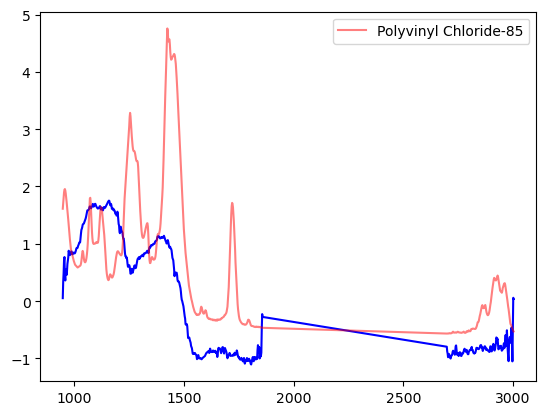

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


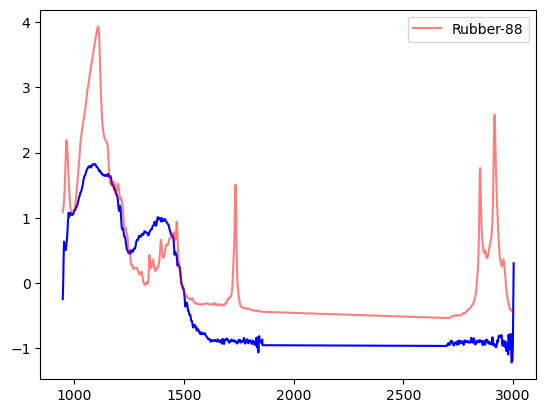

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


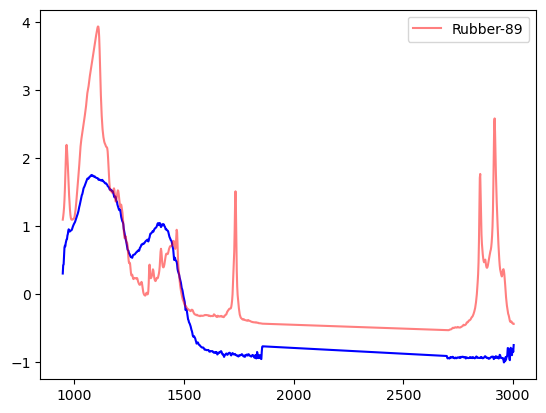

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


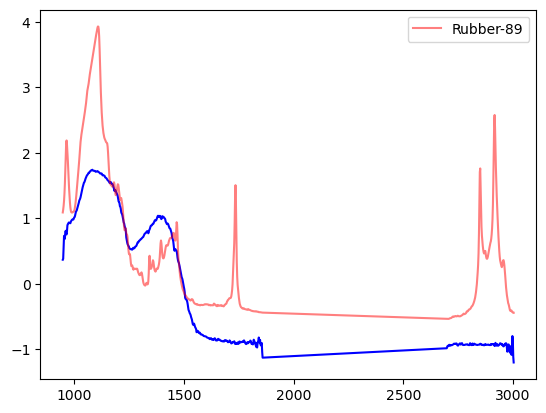

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


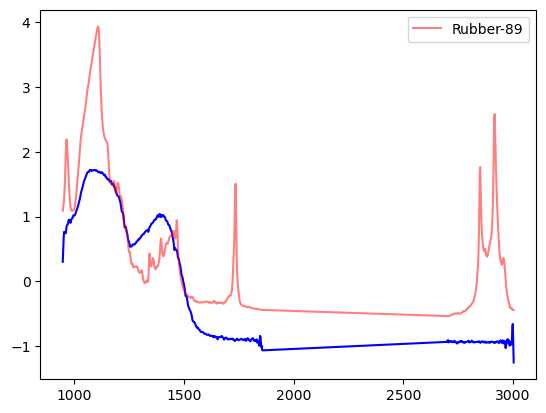

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


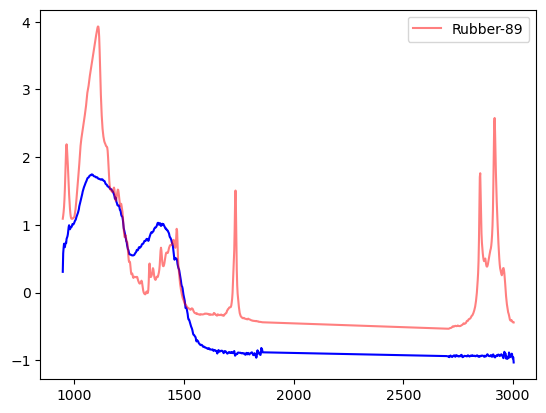

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


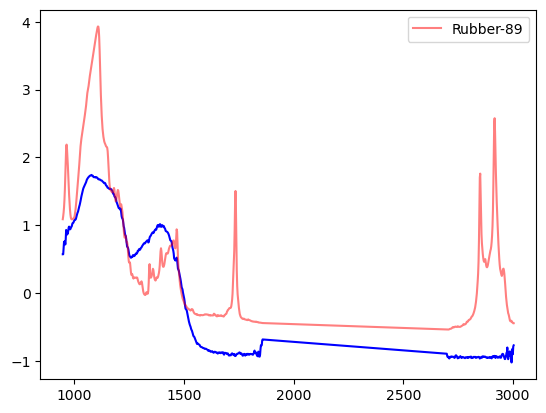

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


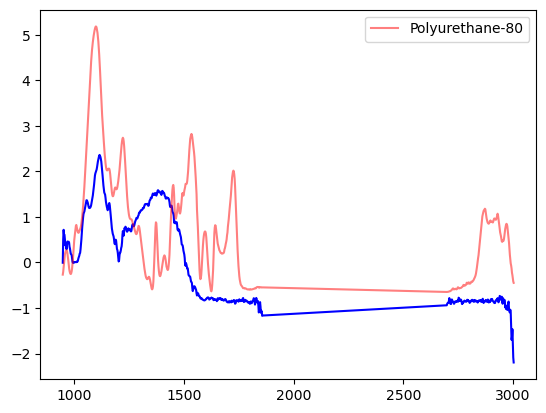

['Cotton', 'Rubber']


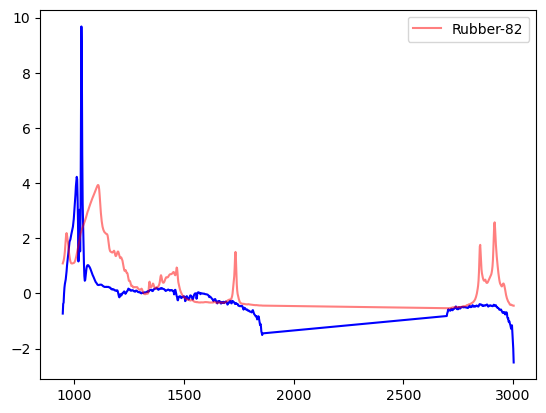

['Acrylic', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


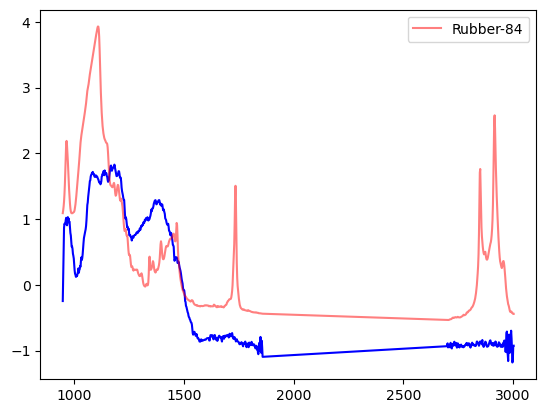

['Rubber']


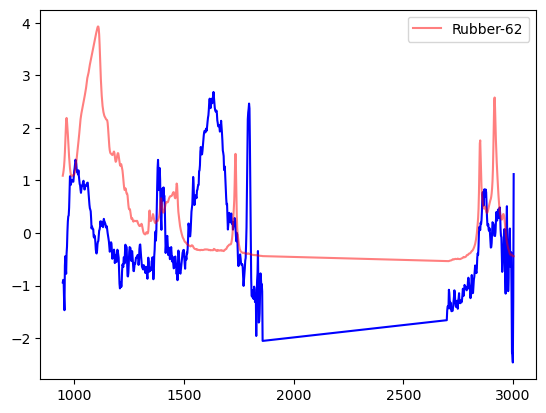

['Polystyrene', 'Rubber']


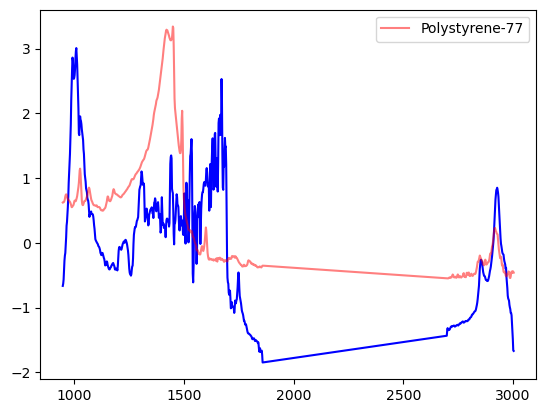

['Cotton', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


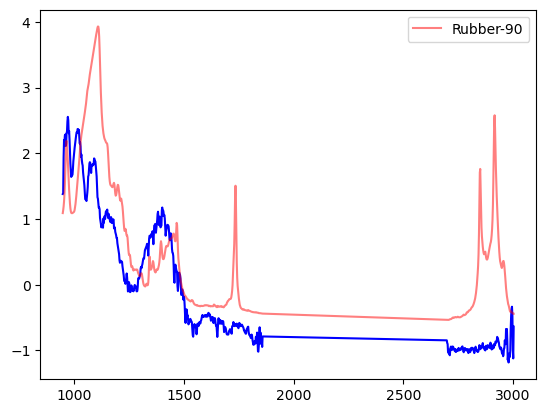

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


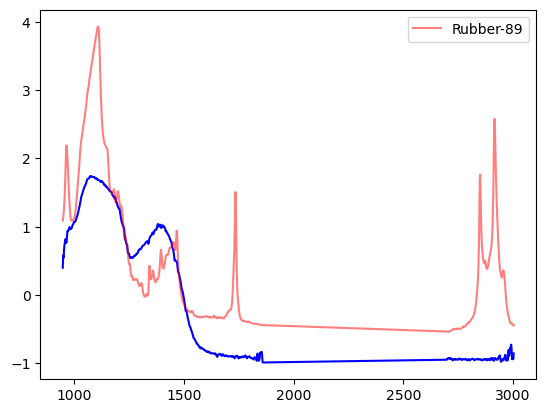

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


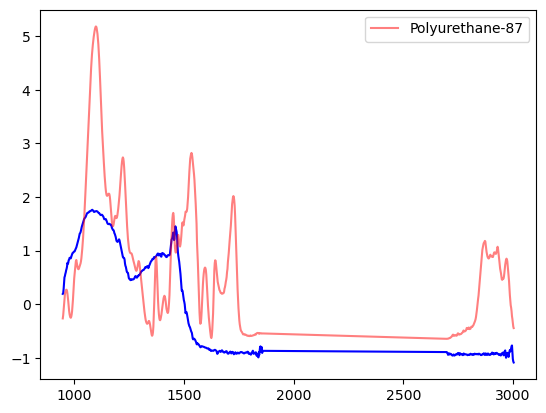

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


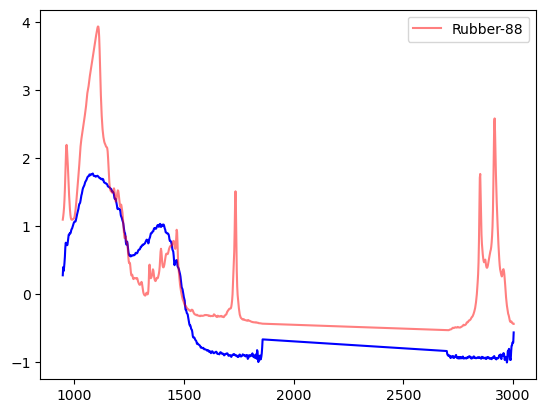

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


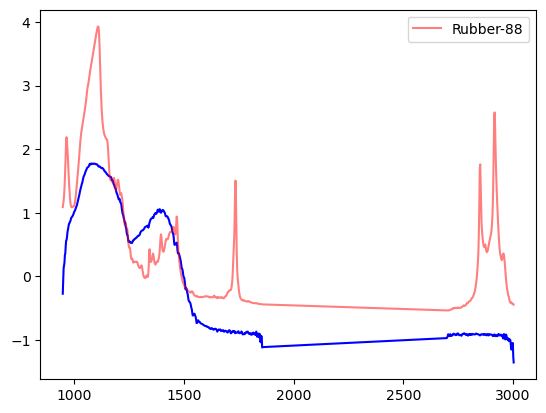

['Acrylonitrile Butadiene Styrene', 'Polyvinyl Chloride', 'Rubber']


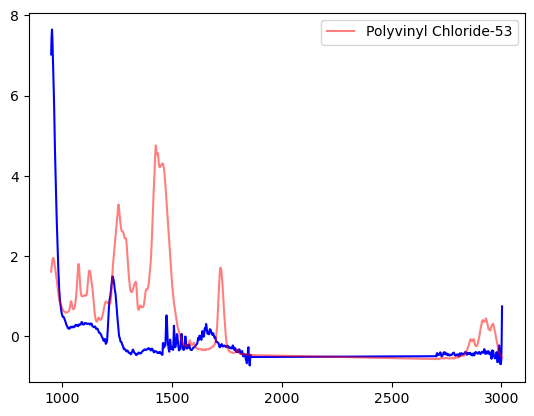

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyvinyl Chloride', 'Rubber']


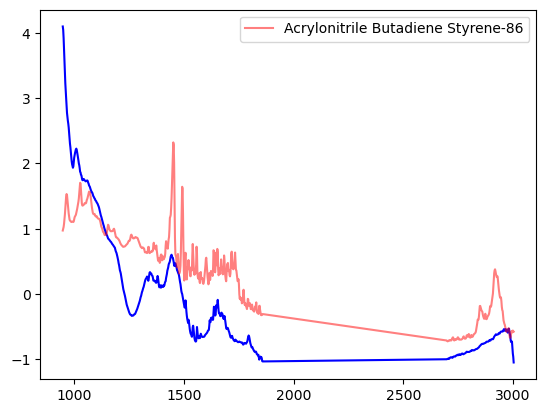

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


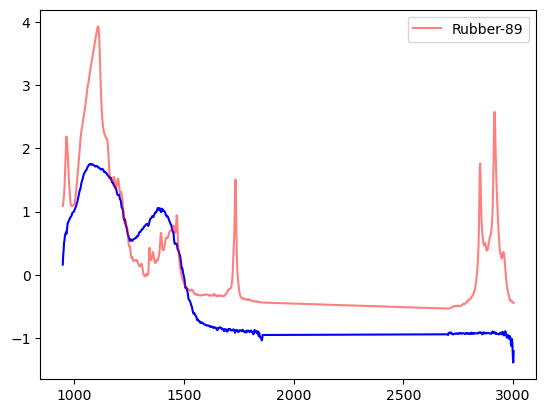

['Acrylonitrile Butadiene Styrene', 'Polyamide', 'Polyethylene Terephthalate', 'Polystyrene']


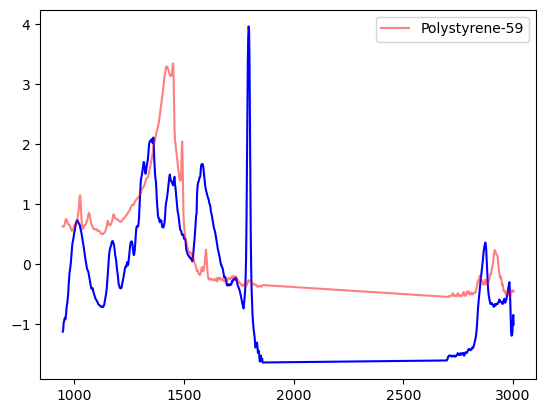

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


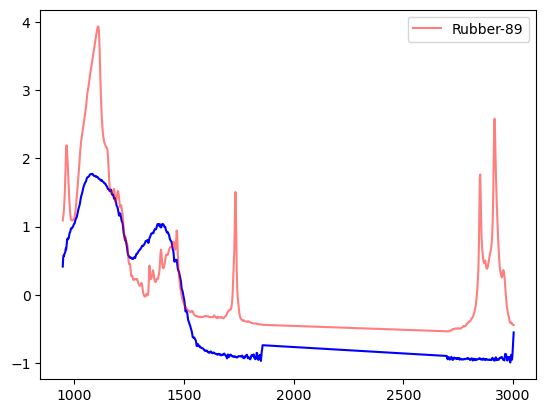

['Acrylonitrile Butadiene Styrene', 'Polyvinyl Chloride', 'Rubber']


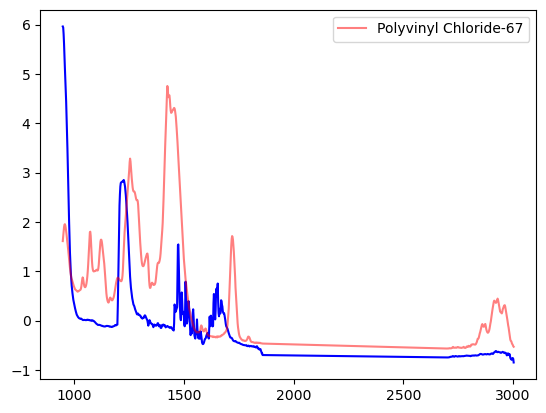

['Acrylonitrile Butadiene Styrene', 'Polyvinyl Chloride']


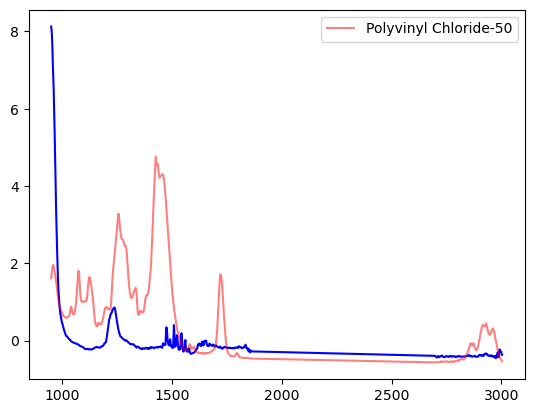

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Rubber']


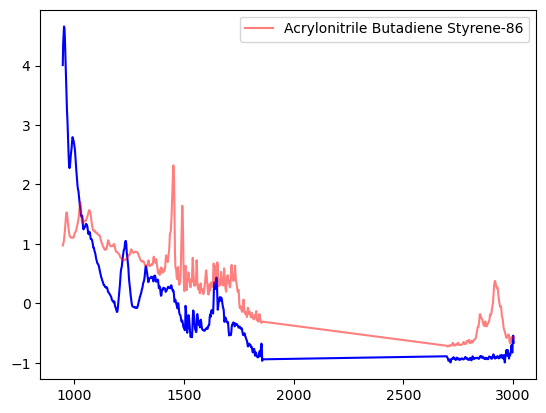

['Acrylonitrile Butadiene Styrene', 'Polyvinyl Chloride', 'Rubber']


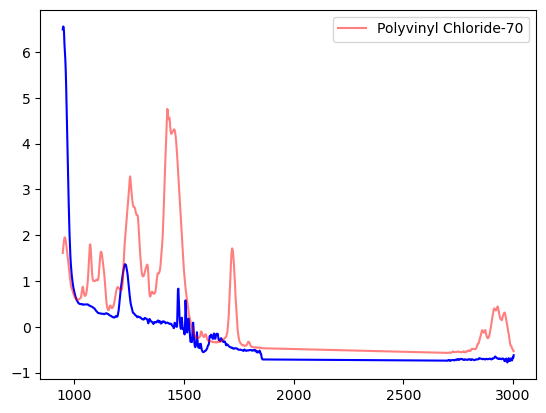

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polystyrene', 'Rubber']


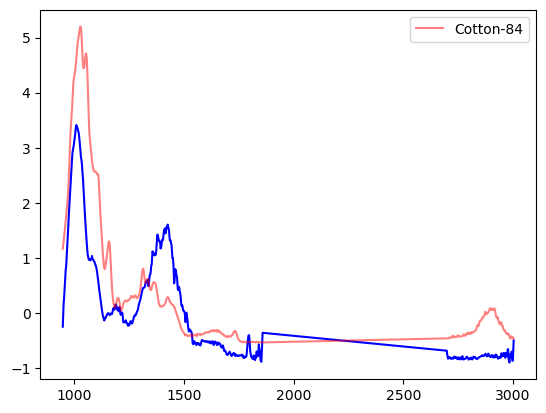

['Cotton', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


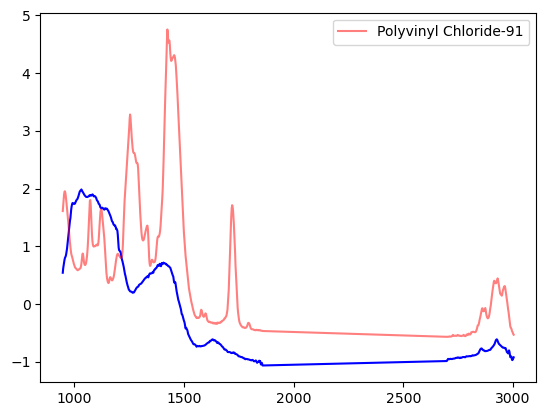

['Cotton', 'Polyurethane', 'Rubber']


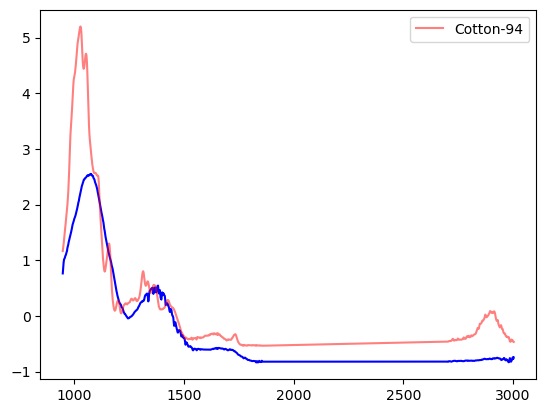

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyurethane', 'Rubber']


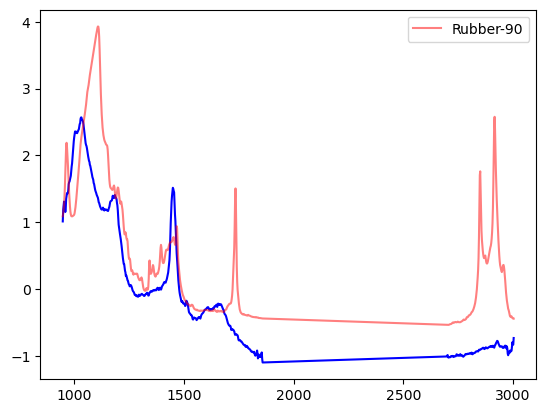

['Polyethylene Terephthalate', 'Polystyrene']


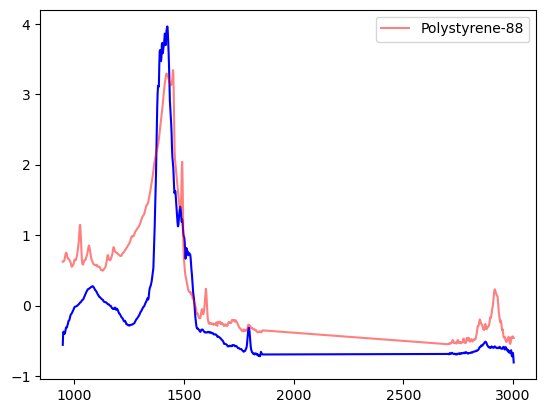

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyvinyl Chloride', 'Rubber']


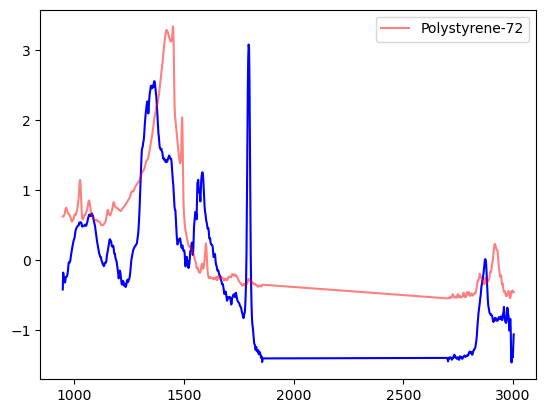

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


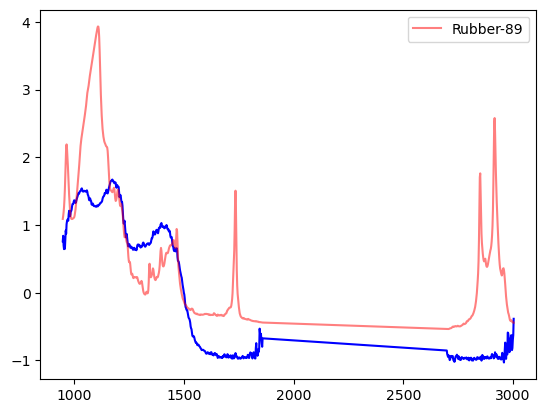

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


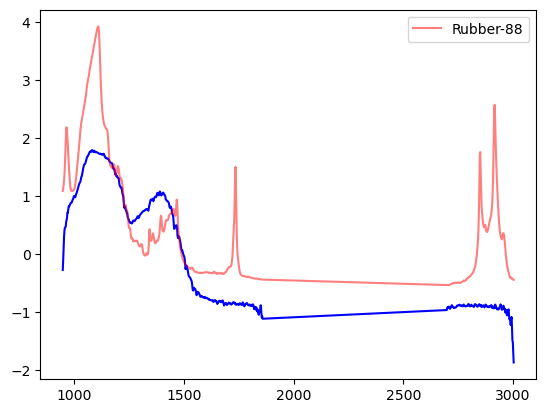

['Rubber']


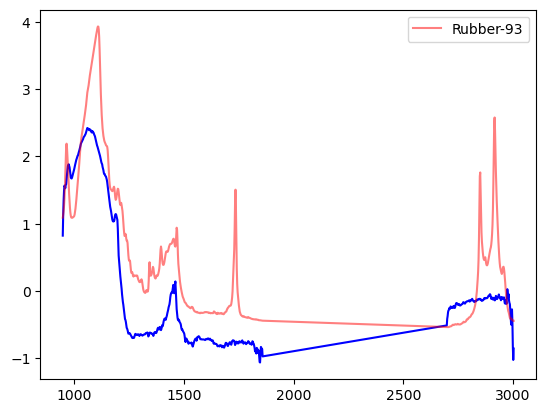

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyurethane', 'Rubber']


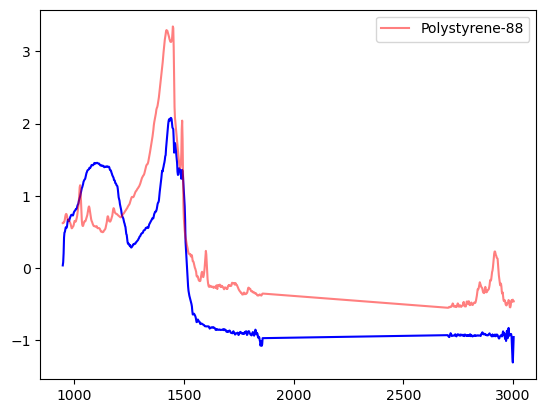

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyurethane', 'Rubber']


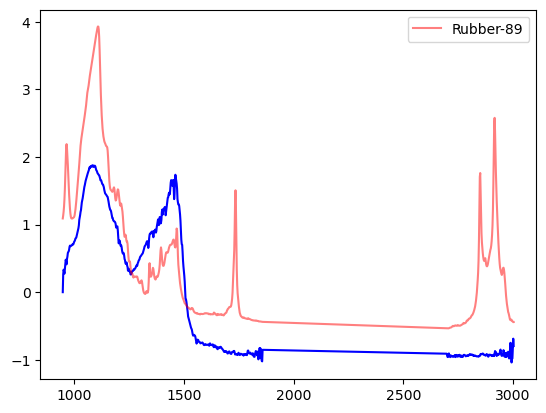

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


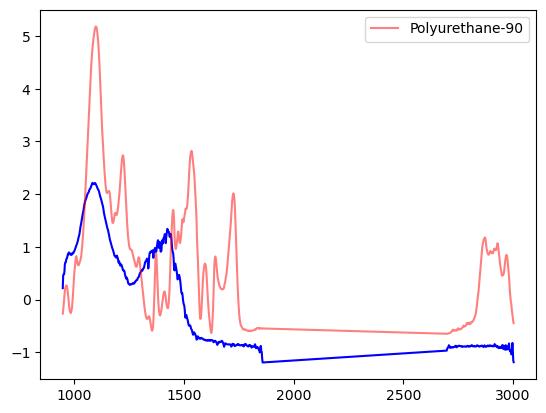

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


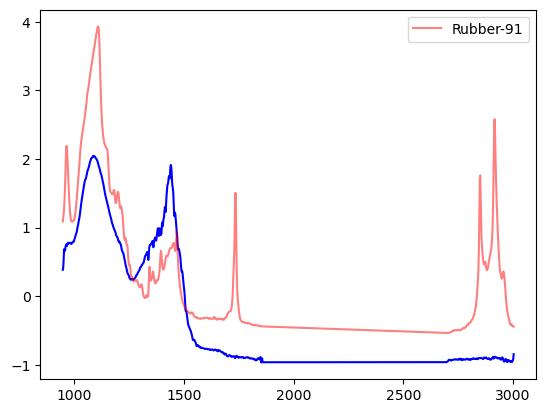

['Acrylic', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


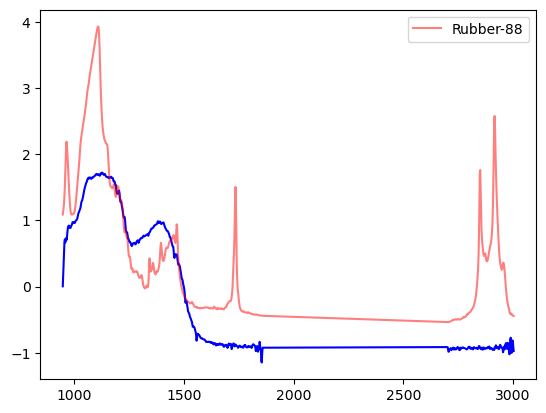

['Polystyrene', 'Polyvinyl Chloride']


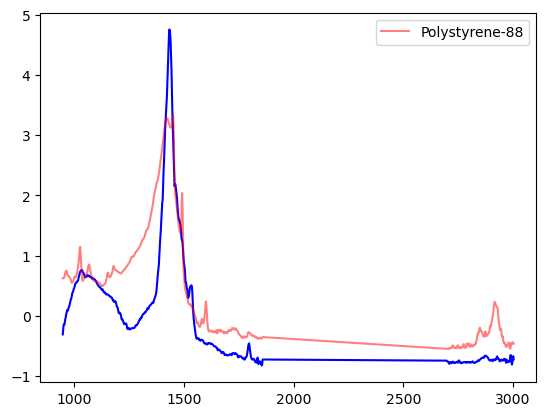

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Rubber']


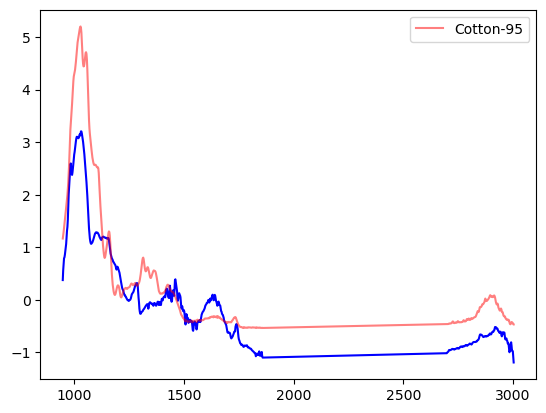

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


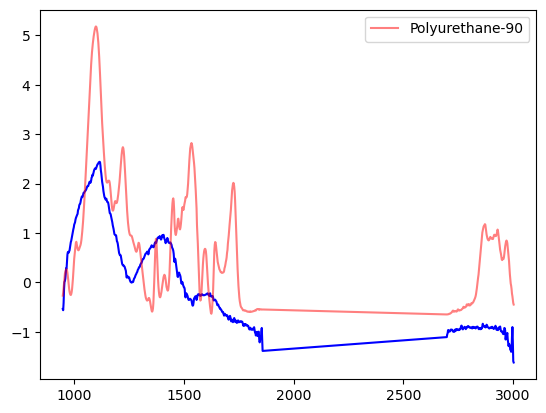

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


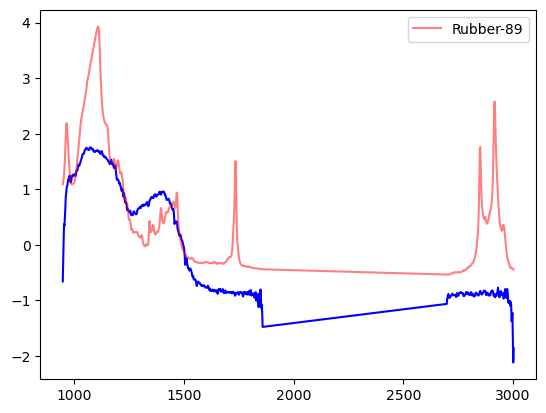

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


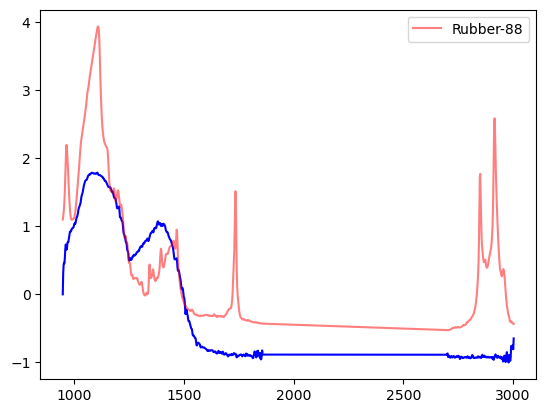

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


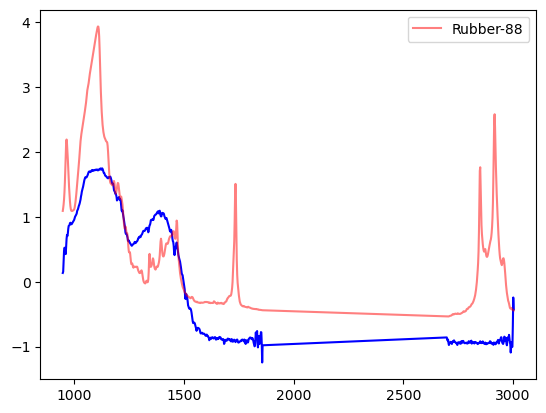

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


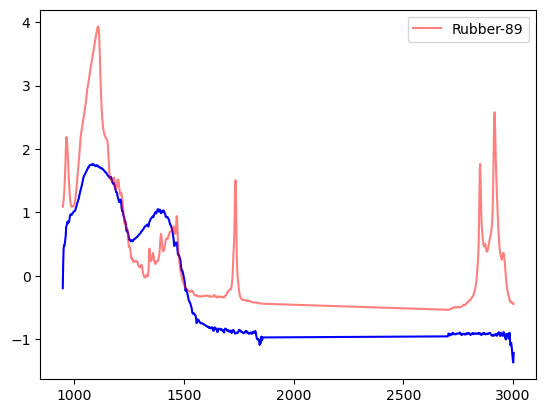

['Acrylonitrile Butadiene Styrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


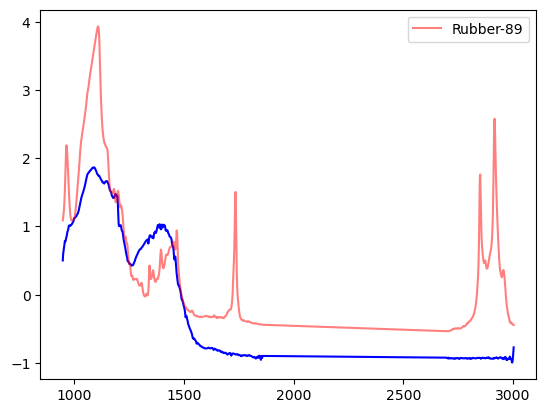

['Polyethylene Terephthalate', 'Polystyrene']


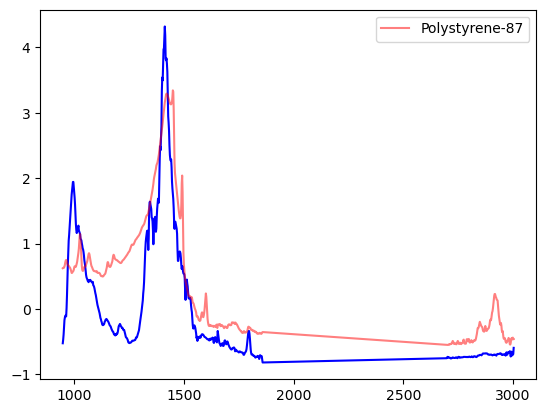

['Cotton', 'Rubber']


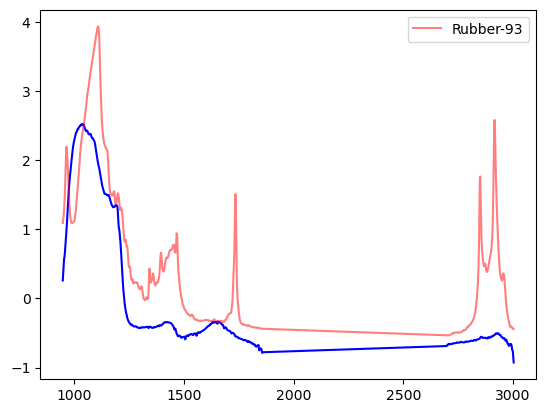

['Acrylonitrile Butadiene Styrene', 'Polystyrene', 'Polyurethane', 'Rubber']


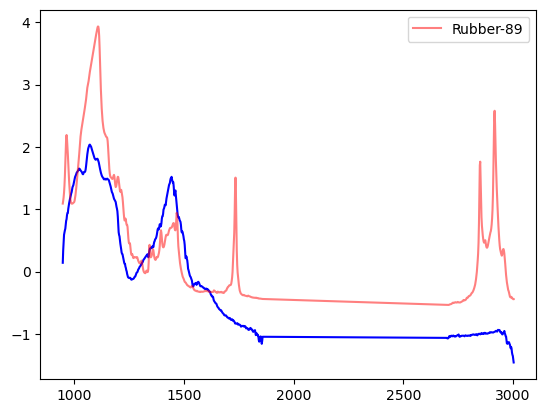

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Rubber']


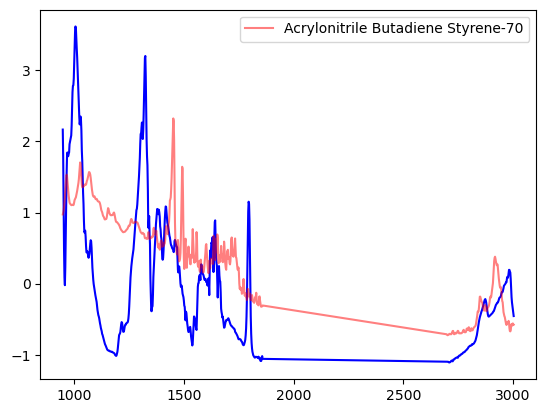

['Cotton', 'Polyurethane', 'Rubber']


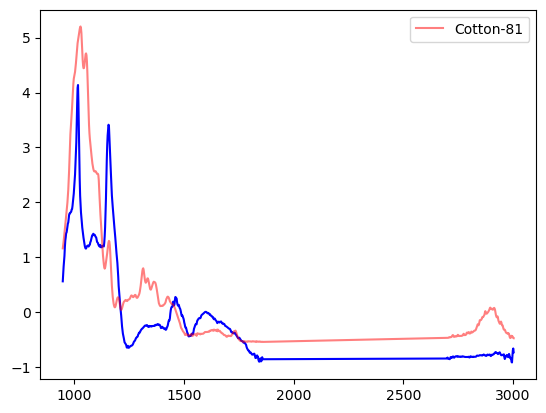

['Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


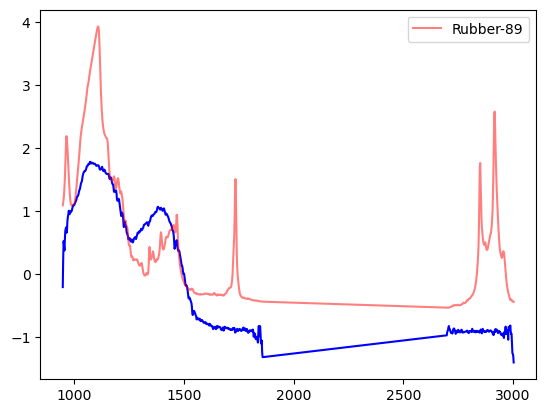

['Cotton', 'Rubber']


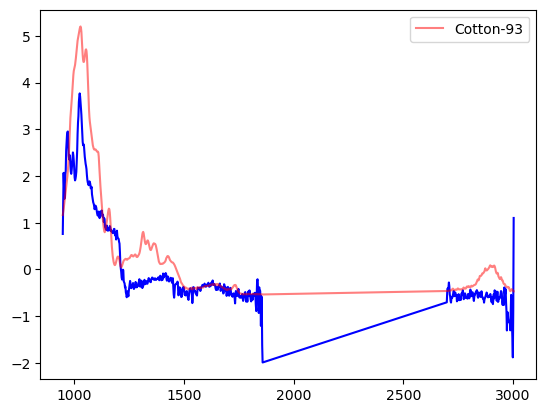

In [1275]:

for i in range(prediction_sets.shape[0]):
    print(prediction_sets_label[i])

    plt.plot(wl_list[idx_range], spectra_df_long_int_pivot.iloc[:,1:].loc[i,idx_range].to_numpy(), c='b')

    #plt.plot(wl_list, X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list[idx_range], -X_train[y_train==pred_hqi[i]].reset_index(drop=True).loc[0,idx_range].to_numpy(), c='r', alpha=.5, label=pred_hqi[i] + '-' + str(round(score_hqi[i]*100)))

    plt.legend()

    plt.show()


In [1310]:
clf = model_logReg(C=0.1)
clf.train_data(x_train[:,idx_range], y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test.loc[:,idx_range])
clf.score(X_test.loc[:,idx_range], y_test)

0.9234972677595629

In [1311]:
pred_log = clf.predict(-spectra_df_long_int_pivot.iloc[:,1:].loc[:,idx_range])
score_log = clf.model.predict_proba(-spectra_df_long_int_pivot.iloc[:,1:].loc[:,idx_range])
#pred_hqi = pred_hqi.to_numpy()
#score_log.max(1)

In [1312]:
cal_smx = clf.model.predict_proba(X_test.loc[:,idx_range])
#smx = 1-smx
cal_labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())}))['id'].to_numpy()
n = cal_smx.shape[0]

val_smx = score_log

alpha = 0.15 # 1-alpha is the desired coverage

In [1314]:
prediction_sets = conform_pref_2(
    cal_smx, 
    val_smx, 
    cal_labels, 
    val_labels=None, 
    n=n, 
    alpha=alpha)

prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(prediction_sets.shape[0])]


['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


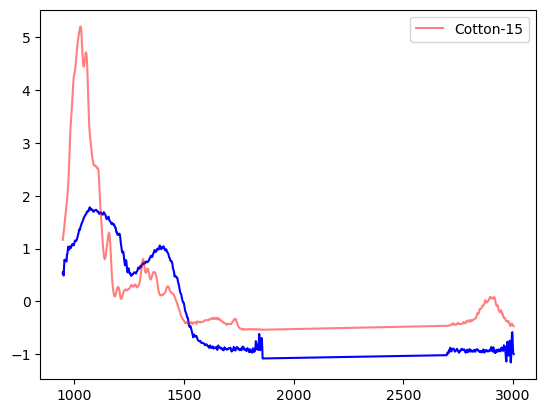

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride']


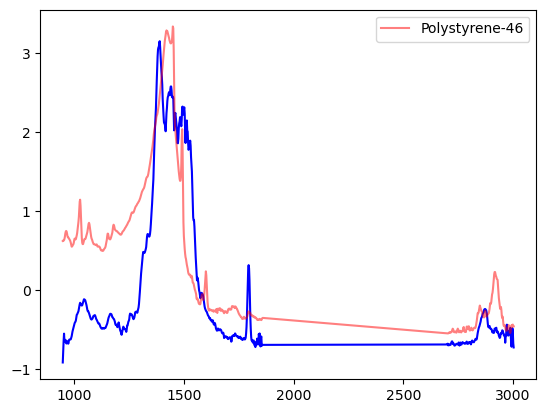

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


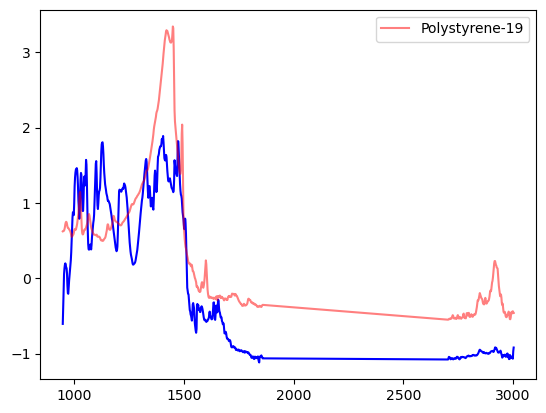

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


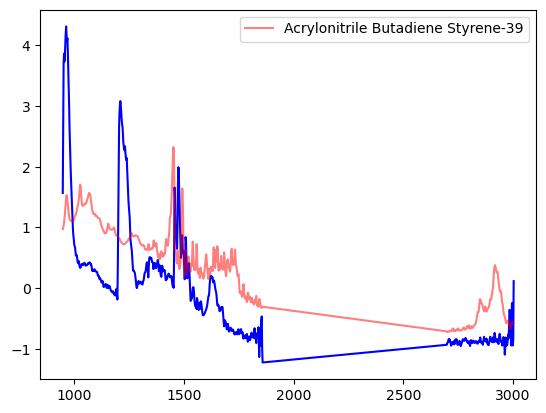

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


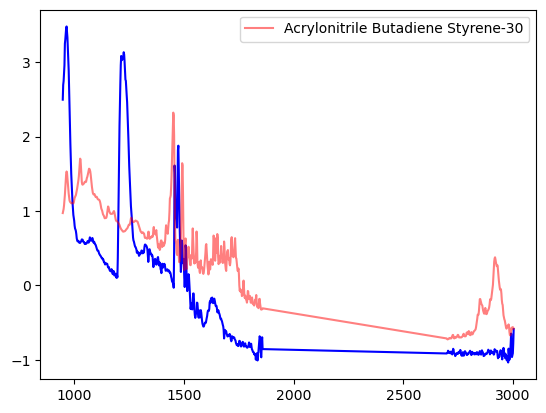

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polylactic acid', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


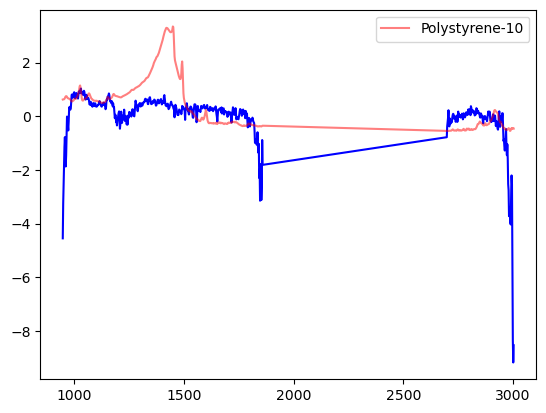

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


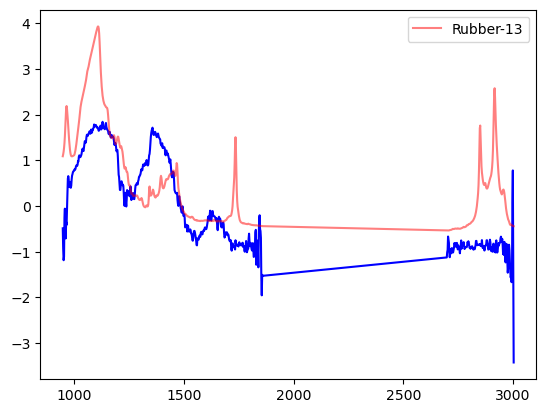

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Rubber']


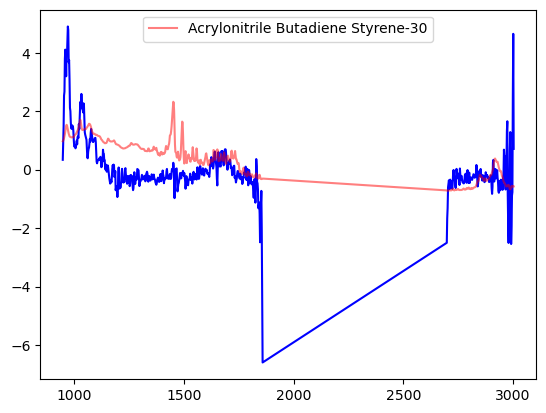

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


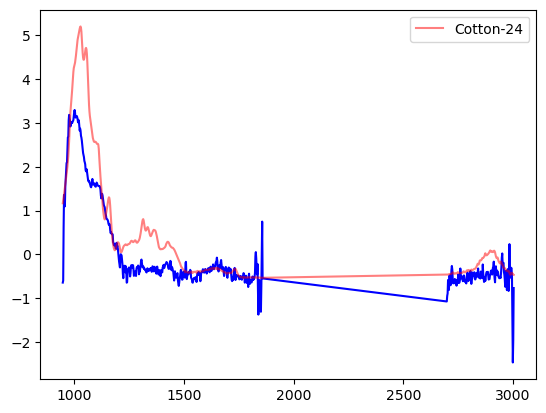

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Rubber']


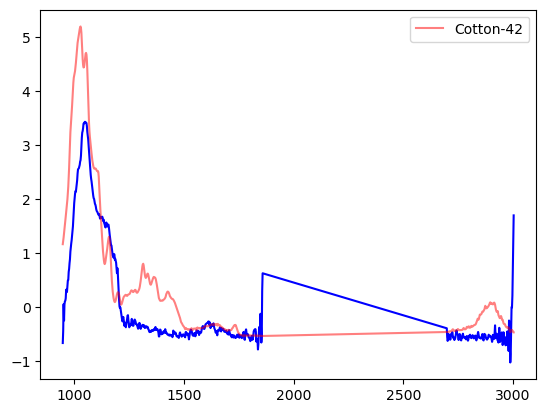

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


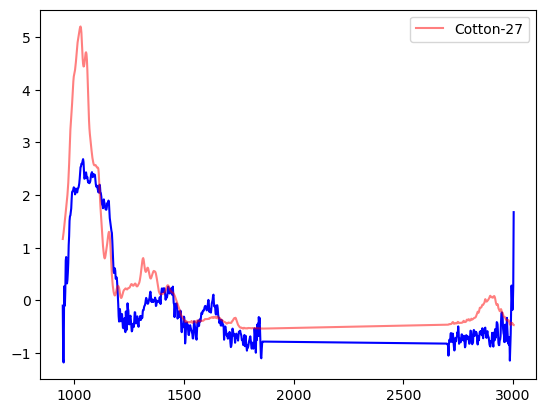

['Acrylic', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polylactic acid', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


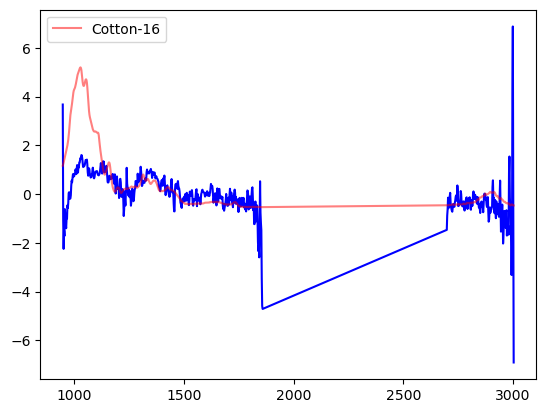

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


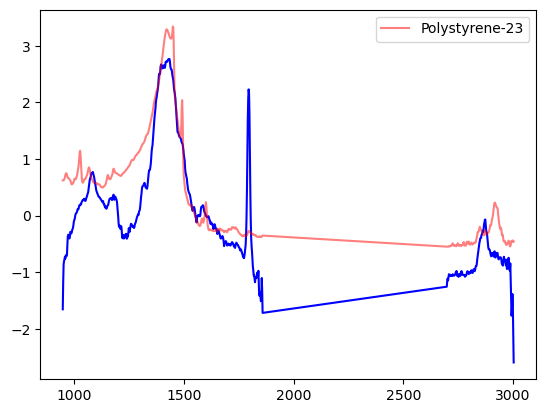

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


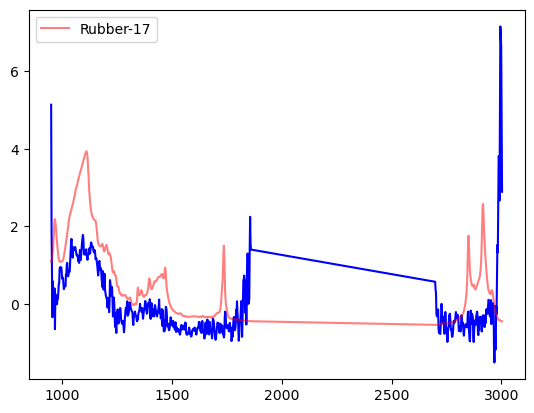

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene', 'Polyethylene Adipate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


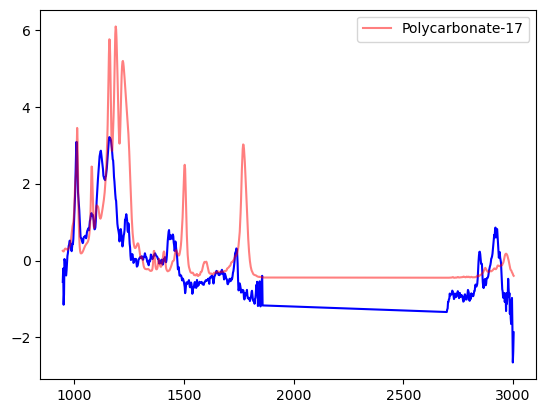

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Polyamide', 'Polyethylene', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyvinyl Chloride', 'Rubber']


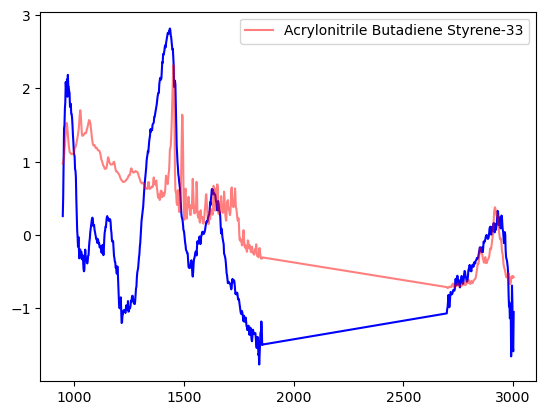

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Vinyl Acetate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


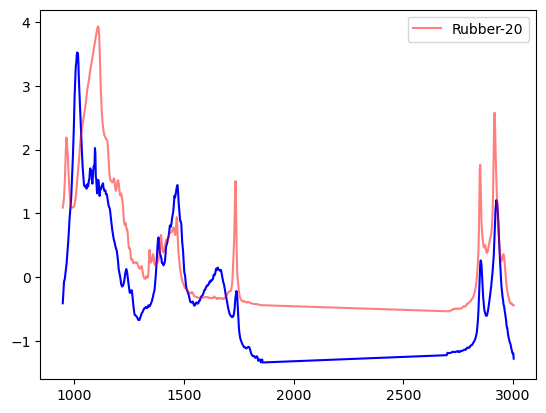

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


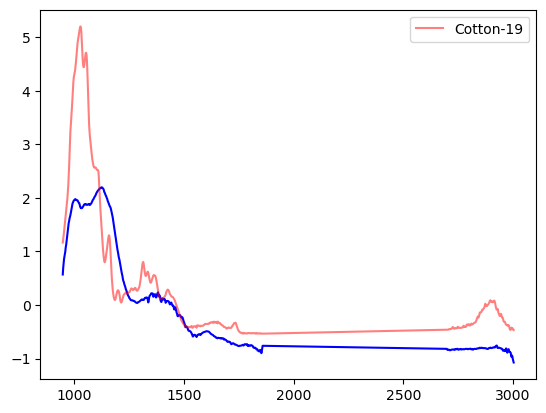

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


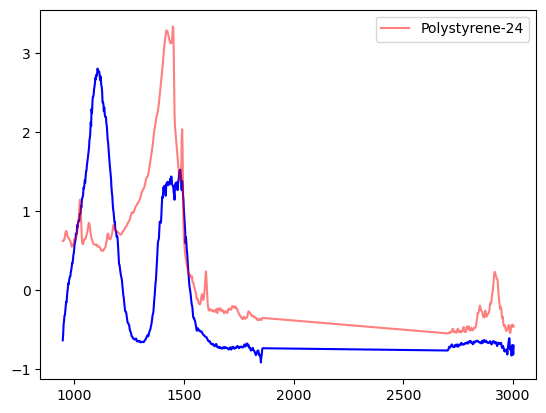

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


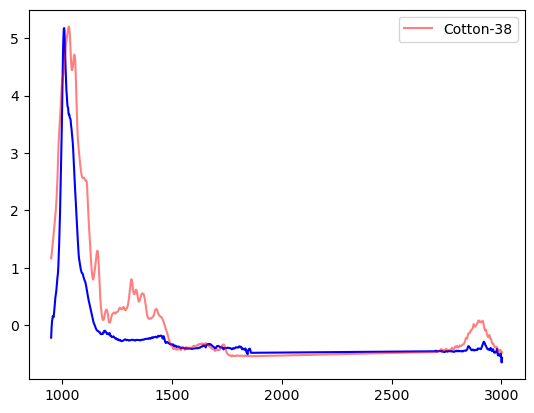

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


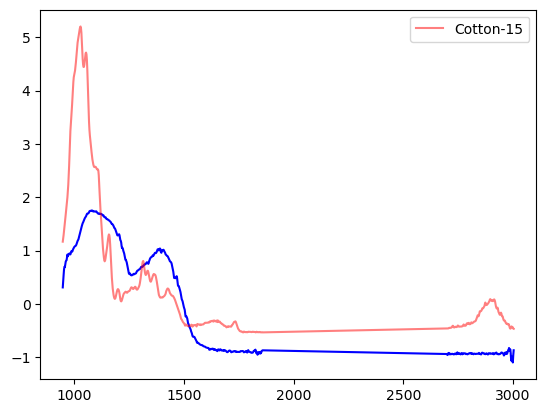

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


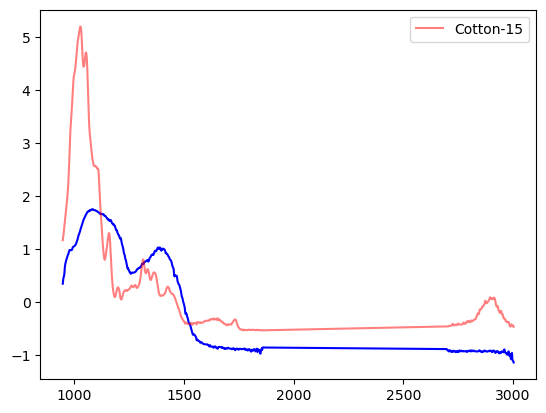

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


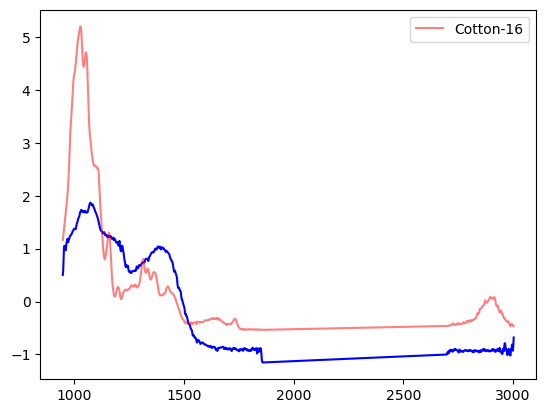

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


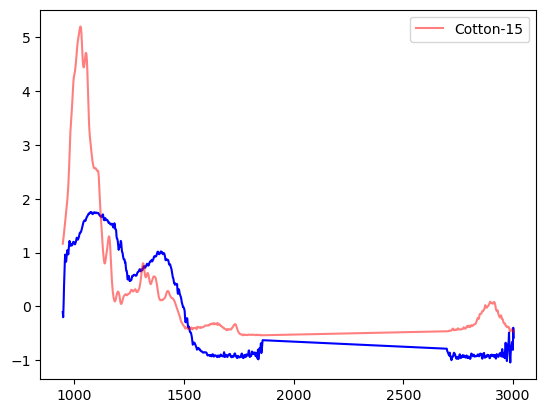

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


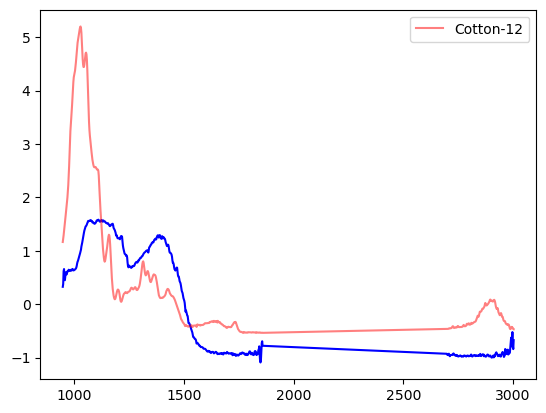

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


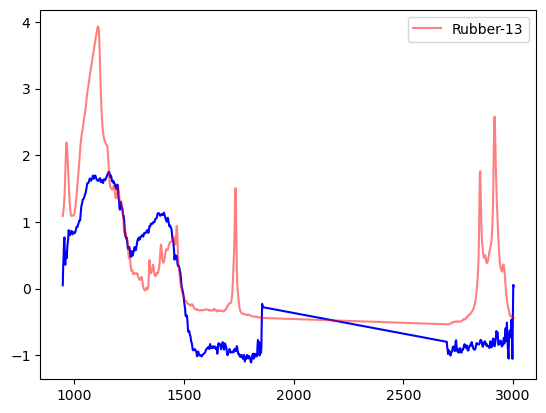

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


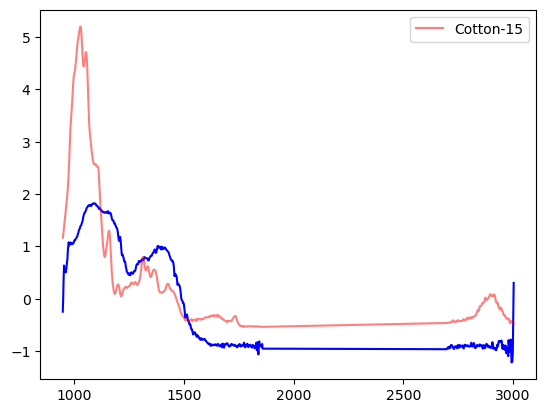

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


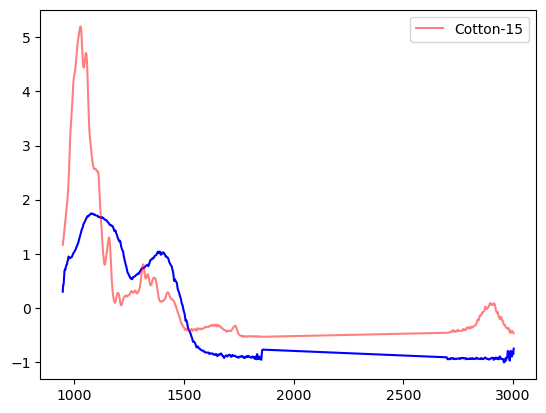

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


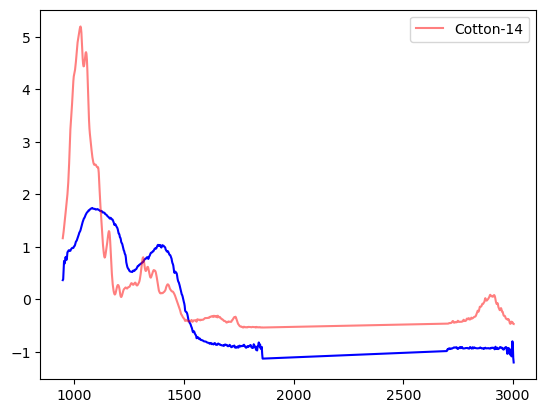

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


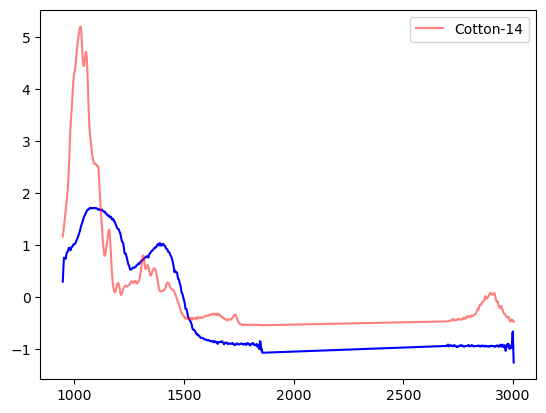

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


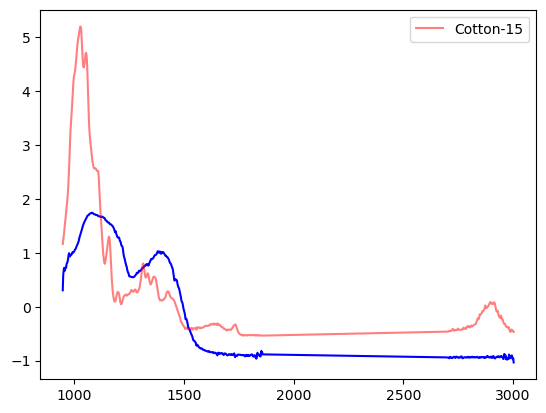

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


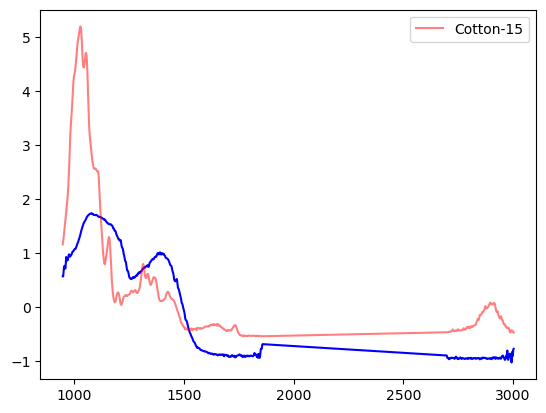

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


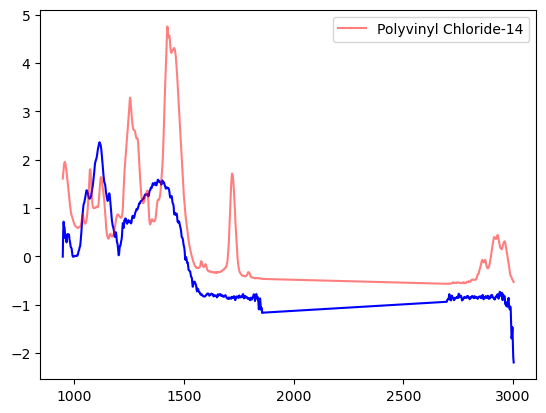

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


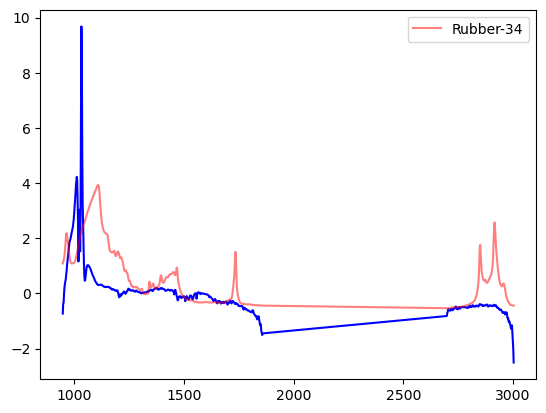

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


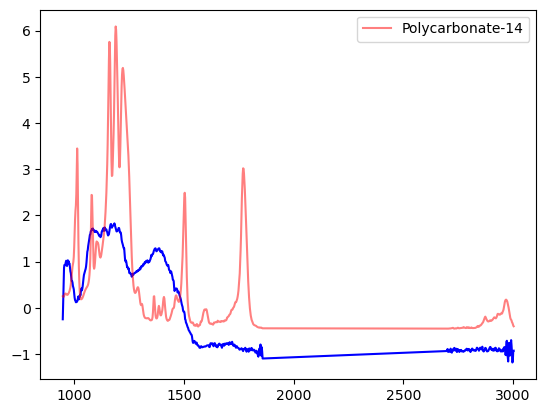

['Acrylic', 'Cotton', 'Polyamide', 'Polyethylene', 'Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polypropylene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


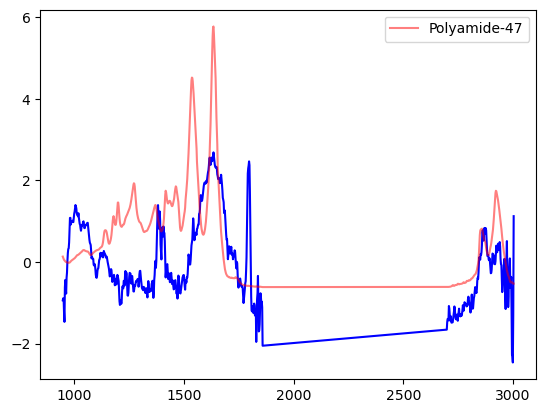

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


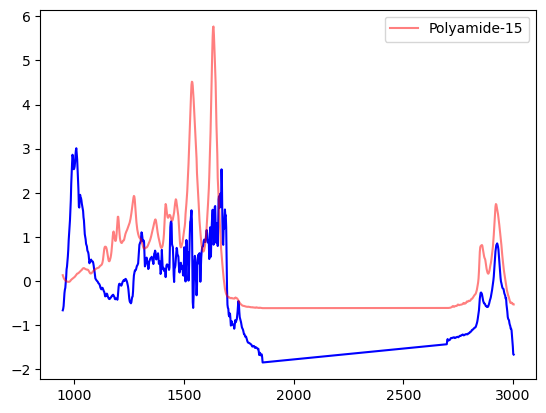

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


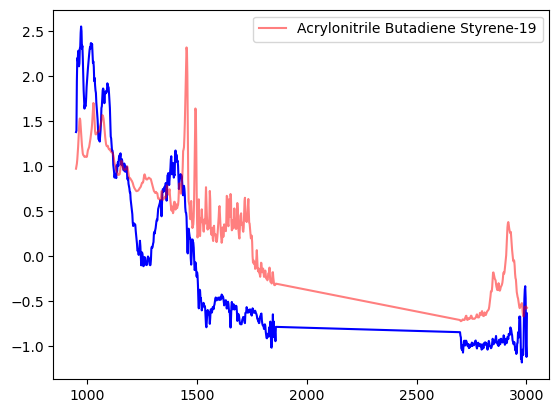

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


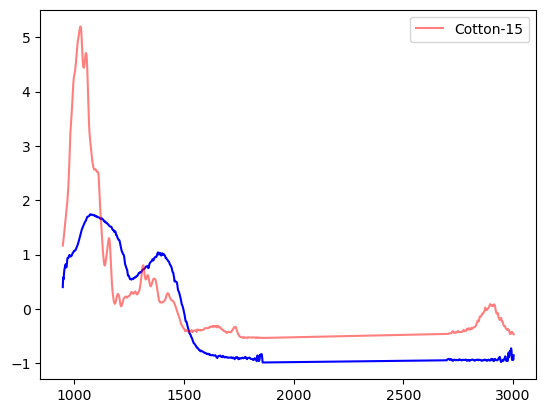

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


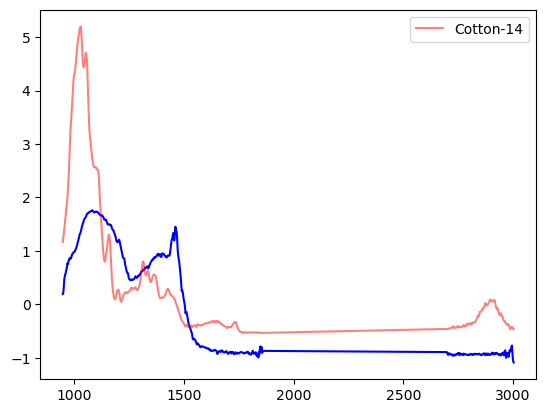

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


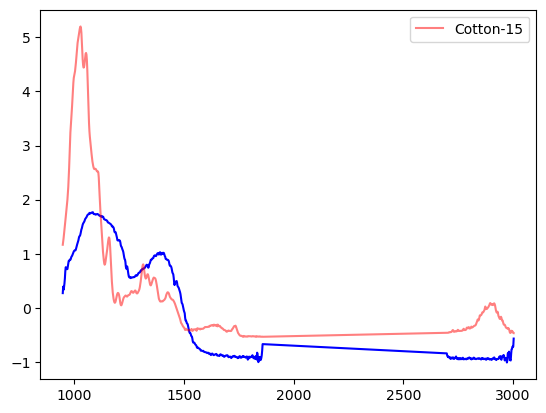

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


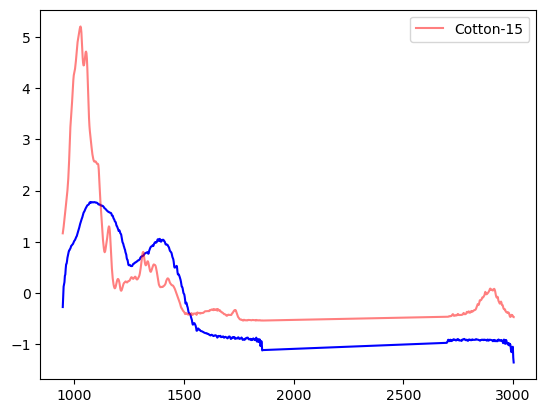

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


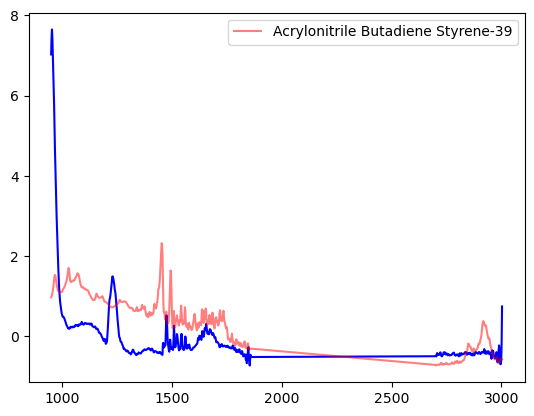

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


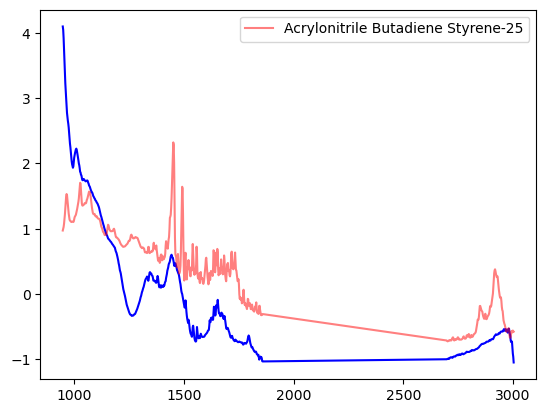

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


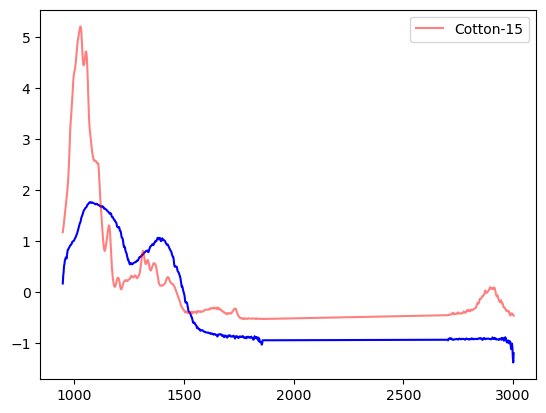

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


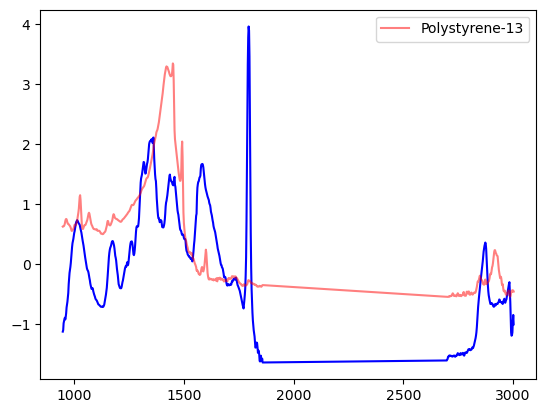

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


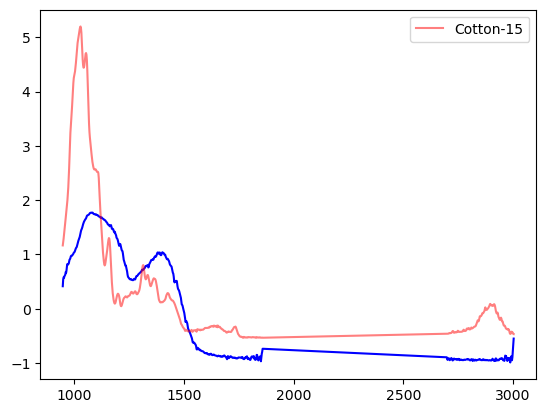

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


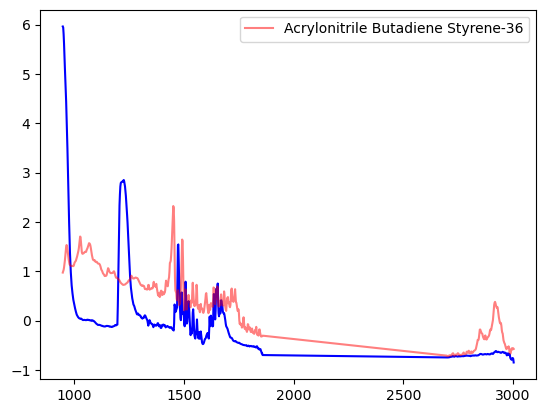

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Polyamide', 'Polyethylene Adipate', 'Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


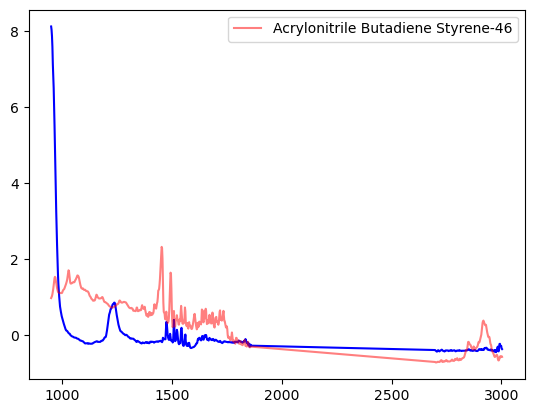

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


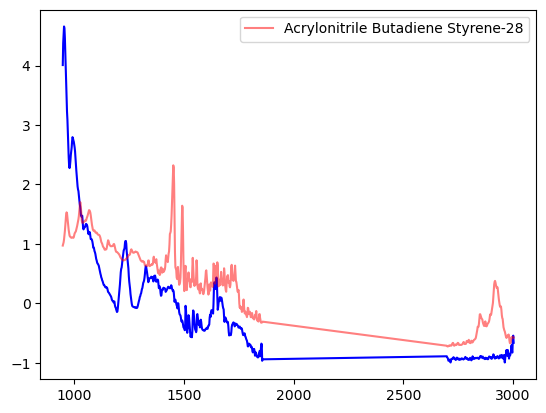

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polyethylene Vinyl Acetate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


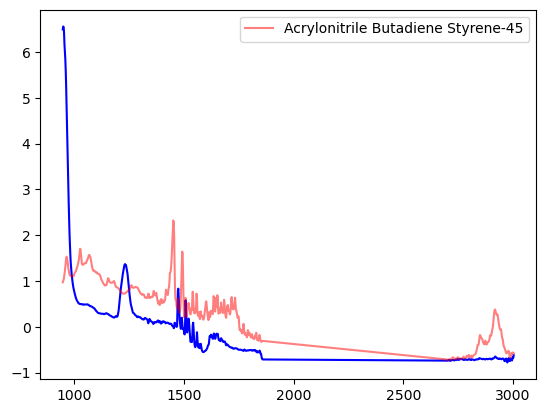

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


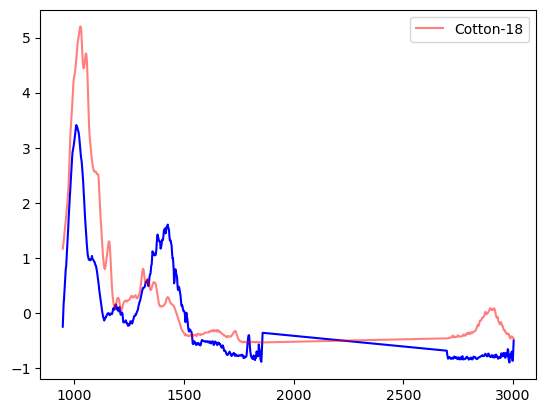

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


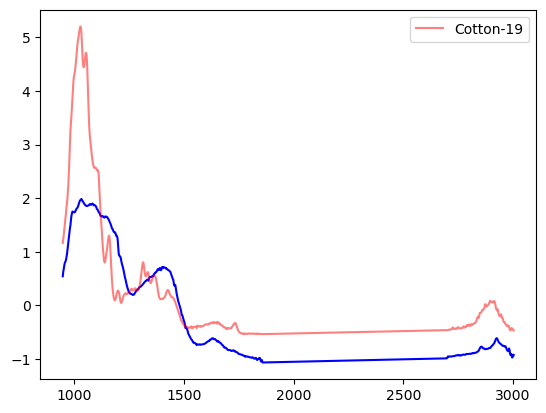

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


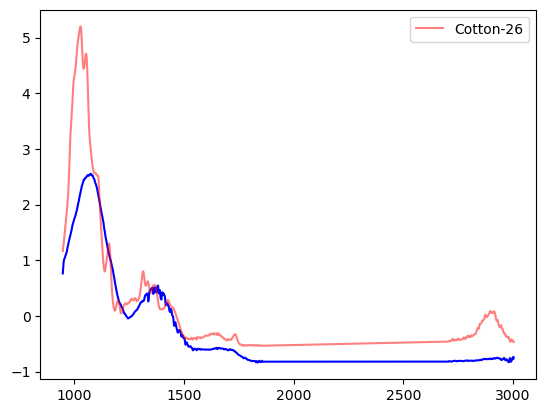

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


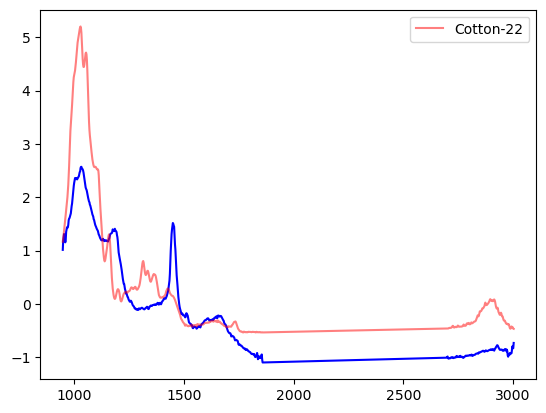

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


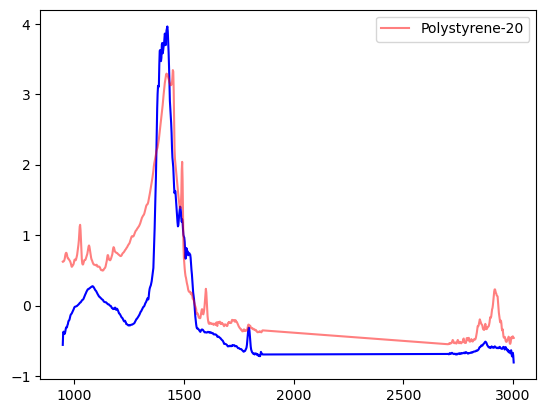

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


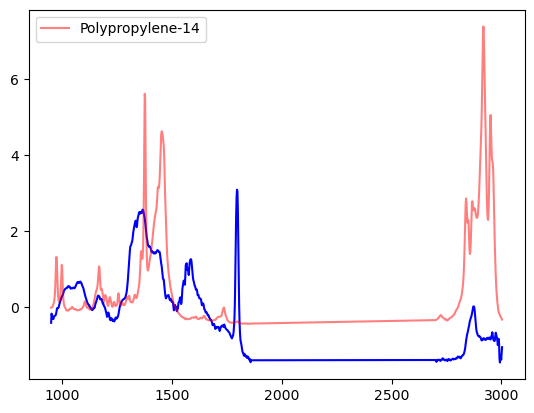

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


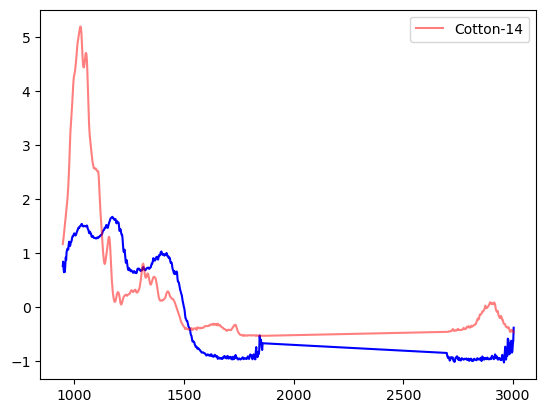

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


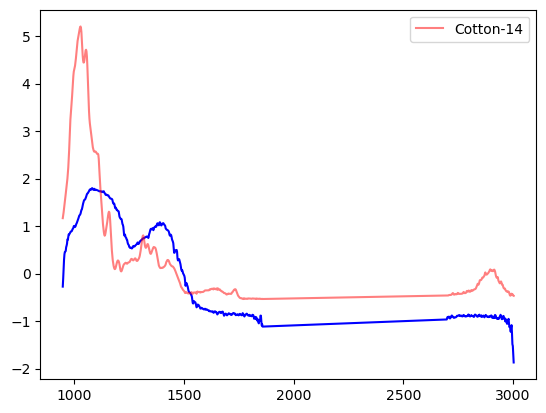

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


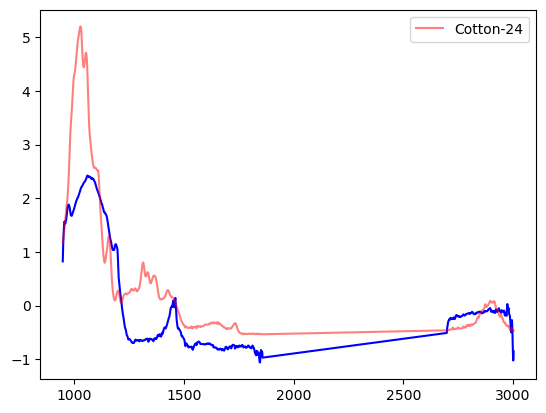

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


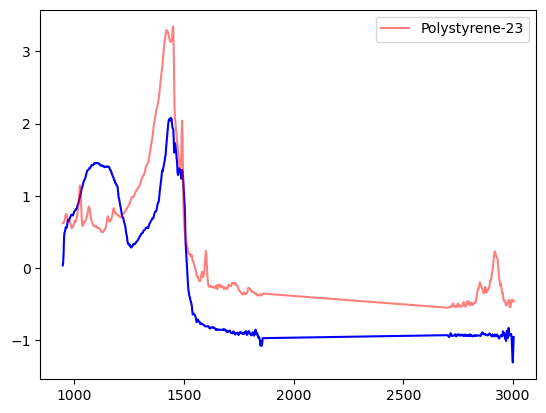

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


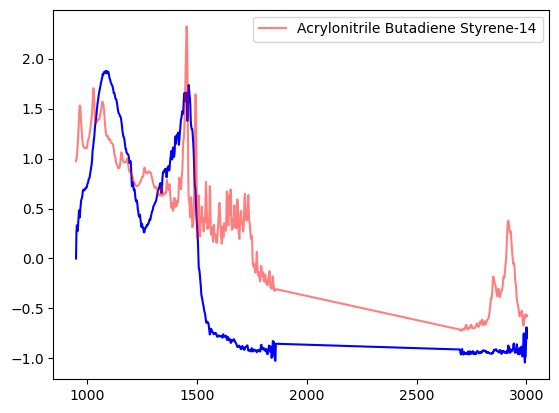

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


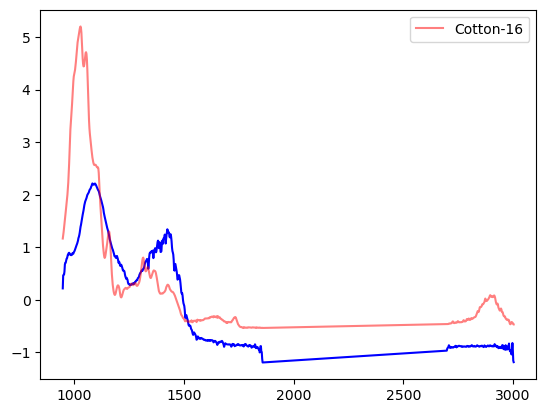

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


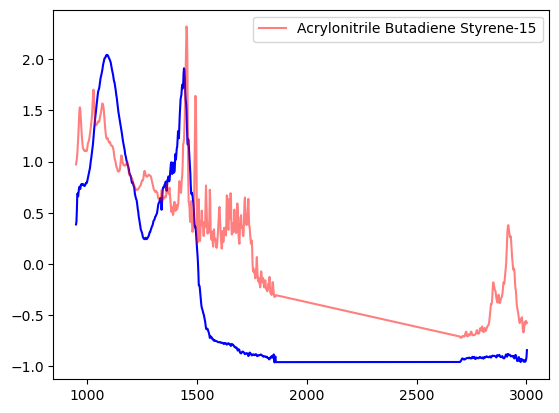

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


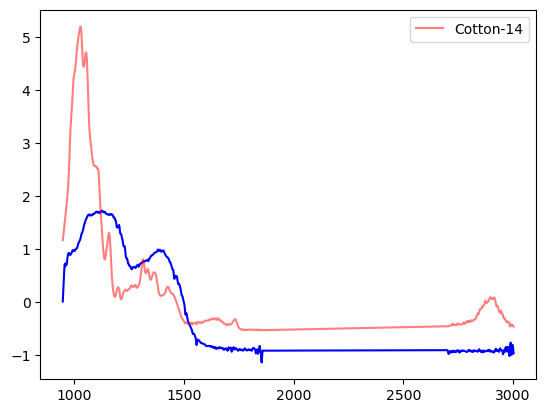

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


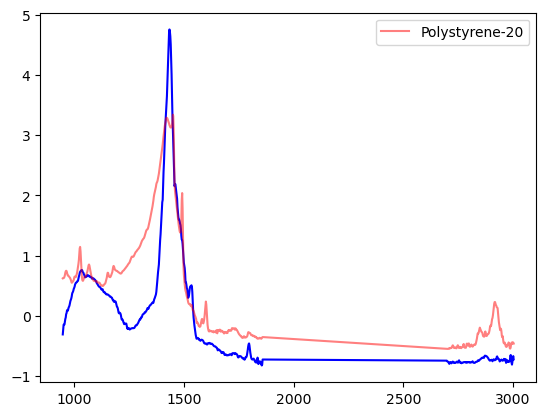

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


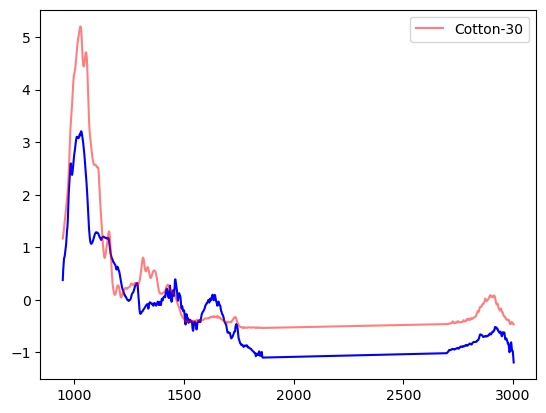

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


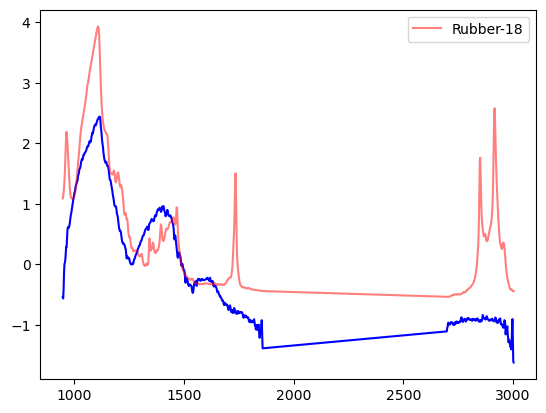

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


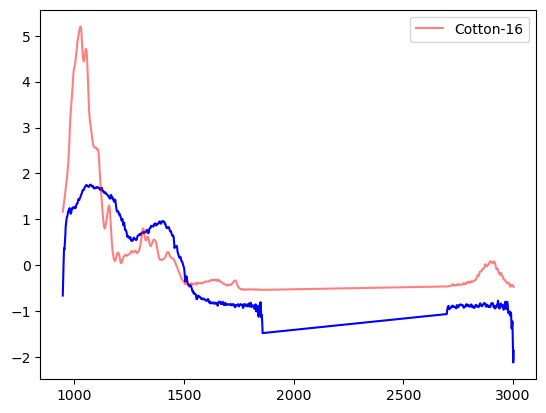

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


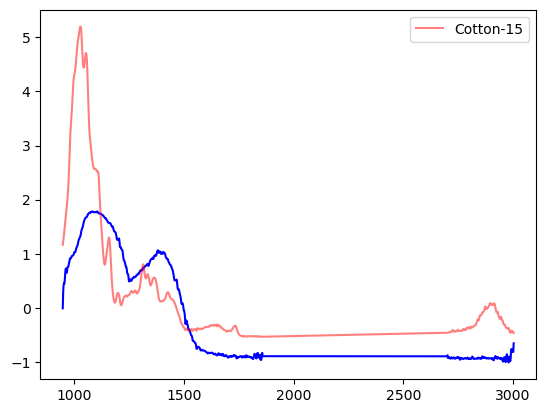

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


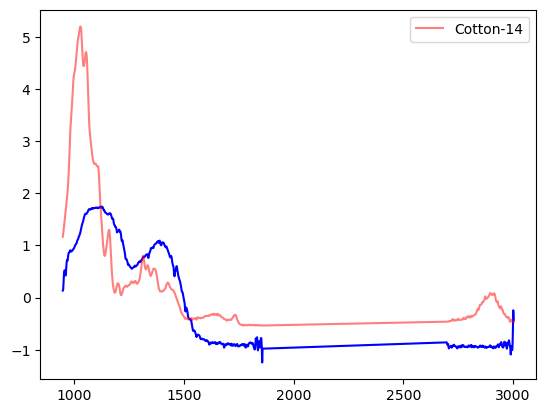

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


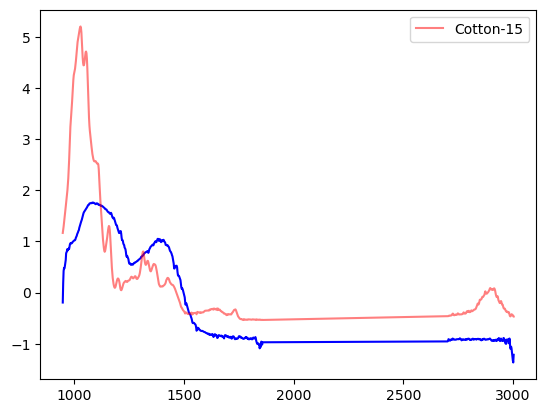

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


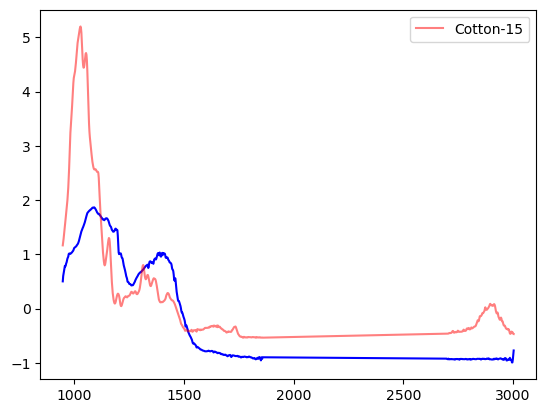

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


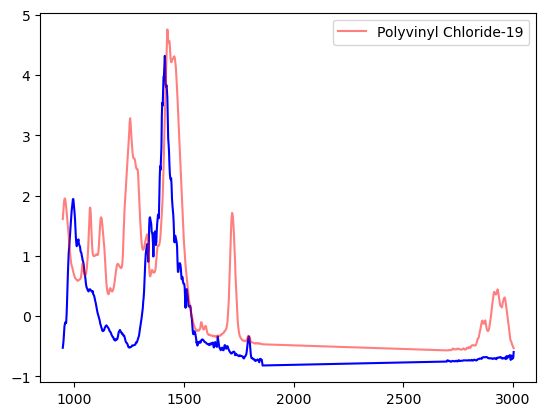

['Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


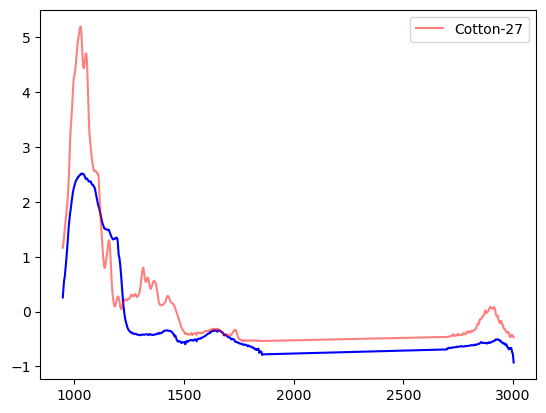

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


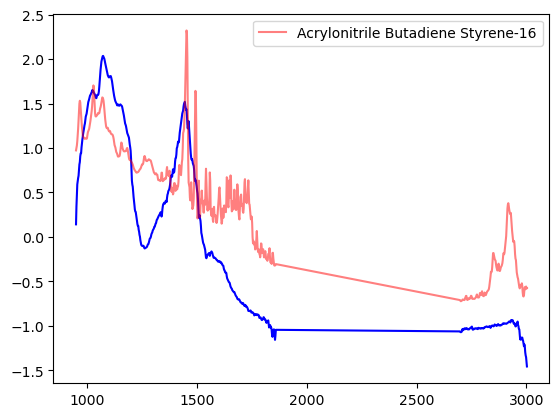

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polyethylene', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyvinyl Chloride', 'Rubber']


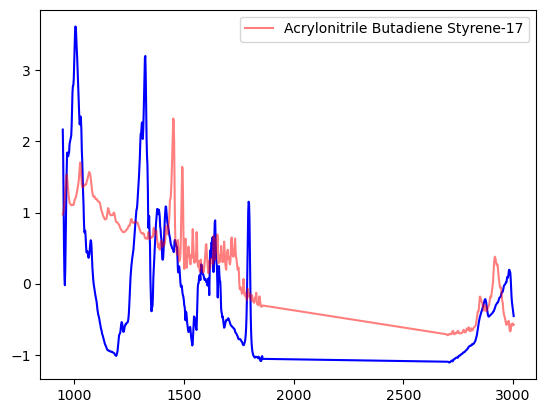

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polylactic acid', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


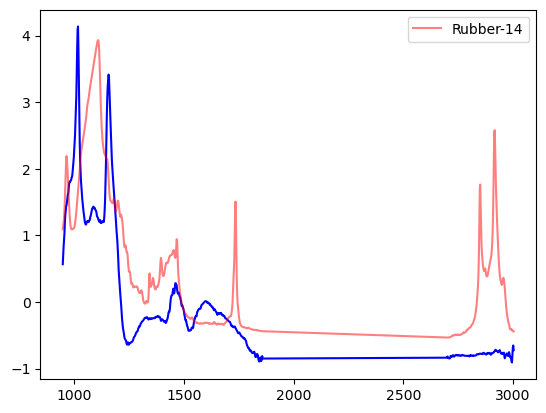

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polycarbonate', 'Polyethylene Adipate', 'Polypropylene', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


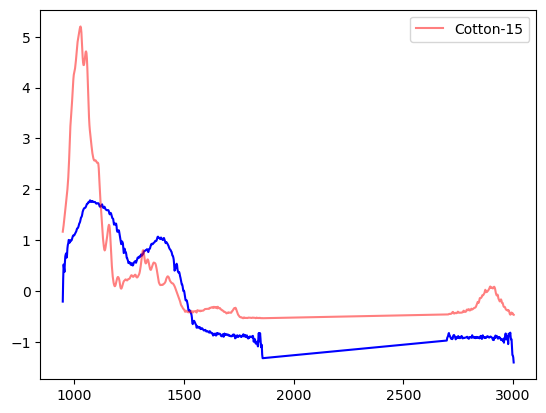

['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton', 'Polyamide', 'Polycarbonate', 'Polyethylene Adipate', 'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber']


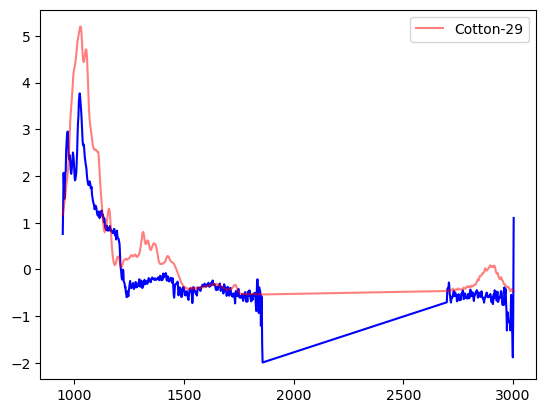

In [1315]:
score_log = score_log.max(1)

for i in range(prediction_sets.shape[0]):
    print(prediction_sets_label[i])

    plt.plot(wl_list[idx_range], spectra_df_long_int_pivot.iloc[:,1:].loc[i,idx_range].to_numpy(), c='b')

    #plt.plot(wl_list, X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list[idx_range], -X_train[y_train==pred_log[i]].reset_index(drop=True).loc[0,idx_range].to_numpy(), c='r', alpha=.5, label=pred_log[i] + '-' + str(round(score_log[i]*100)))

    plt.legend()

    plt.show()


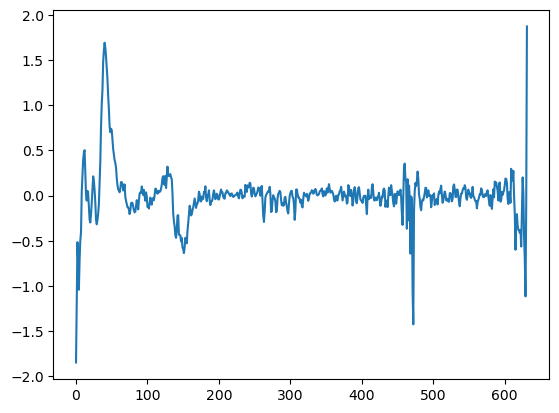

In [1359]:
#import numpy as np
#import statsmodels.api as sm
#lowess = sm.nonparametric.lowess
x = wl_list[idx_range].to_numpy()
y = spectra_df_long_int_pivot.iloc[:,1:].loc[i,idx_range].to_numpy()
z = lowess(y, x)
w = lowess(y, x, frac=1./7)

#plt.scatter(x,y)
#plt.scatter(w[:,0],w[:,1])

plt.plot(y - w[:,1])

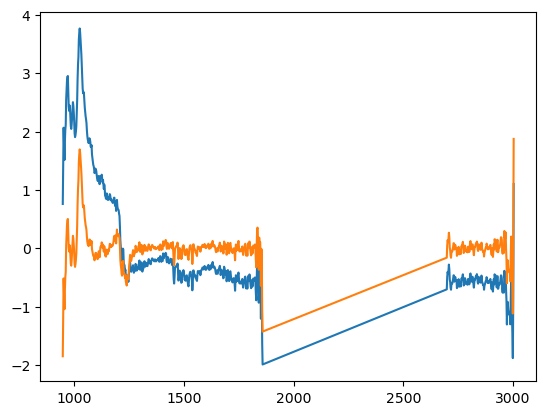

In [1360]:
plt.plot(x,y)
plt.plot(x, y - w[:,1])

In [1361]:
np.power(np.diff(y), 2).sum()

15.949340352178613

In [1362]:
np.power(np.diff(y, 10), 2).sum()

292278.8579540246